In [ ]:
import os
import sys
import clr
import pandas as pd


# ==========================================================
# 1. CONFIGURACIÓN DE LA CONSULTA
# ==========================================================

TAGS = [

    # ======================================================
    # BALANCE DE VAPOR
    # ======================================================

    # Vapor HS importado desde límite de batería
    "FCCFI30303BM.DACA.PV",

    # Vapor HS exportado desde FCC
    "FCCFI30303AM.DACA.PV",

    # Vapor HS generado dentro de FCC
    "FCCFI12901M.DACA.PV",

    # Consumo de vapor compresor de gases
    "RG1FI00303.DACA.PV",


    # ======================================================
    # BOMBAS DE FONDOS P-017A / P-017B
    # ======================================================

    # Velocidad bomba de fondos P-017A
    "FCCSI80810A.DACA.PV",

    # Velocidad bomba de fondos P-017B
    "FCCSI80810B.DACA.PV",


    # ======================================================
    # CONDENSADOR / VACÍO
    # ======================================================

    # Presión absoluta del condensador
    "FCCPI13162M.PV",

    # Flujo de agua de mar
    "FCCFI30202.DACA.PV",

    # Temperatura entrada agua de mar
    "FCCTI30204.DACA.PV",

    # Temperatura salida agua de mar
    "FCCTI30208.DACA.PV",

    # Presión entrada agua de mar
    "FCCPI30204.DACA.PV",


    # ======================================================
    # SOPLADOR / TURBINA
    # ======================================================

    # Flujo de aire del soplador
    "FCCFI10561M.DACA.PV",

    # Temperatura descarga soplador
    "FCCTI10464.PV",

    # Presión descarga soplador
    "FCCPI10463.PV",

    # RPM turbina
    "FCCSI70129B.PV",

    # Presión vapor entrada turbina
    "FCCPI10405M.PV",

    # Temperatura vapor entrada turbina
    "FCCTI10401M.PV",

    # Apertura antisurge
    "FCCZI10461.PV",


    # ======================================================
    # REGENERADOR
    # ======================================================

    # Presión regenerador
    "FCCPC11203.PIDA.PV",

    # Posición válvula SV3
    "FCCPDX12601B.DACA.PV",


    # ======================================================
    # EYECTORES
    # ======================================================

    # Presión vapor HS hacia eyectores
    "FCCPI30304.DACA.PV",

    # Temperatura vapor HS hacia eyectores
    "FCCTI30304.DACA.PV",
]


# ==========================================================
# 2. RANGO DE TIEMPO
# ==========================================================

INICIO = "2026-06-01 00:00:00"
FIN = "2026-08-18 23:59:00"


# ==========================================================
# 3. INTERVALO
# ==========================================================

INTERVALO_MIN = 1


# ==========================================================
# 4. TIPO DE MUESTREO
# ==========================================================

# "Average"  = promedio dentro de cada intervalo
# "Snapshot" = valor puntual

TIPO_MUESTREO = "Average"


# ==========================================================
# 5. CONSUMO NOMINAL BOMBA DE FONDOS
# ==========================================================

CONSUMO_BOMBA_FONDOS = 8396  # kg/h

# La velocidad nominal es 1200 rpm,
# pero si supera 1000 rpm se considera en servicio
RPM_MIN_BOMBA_FONDOS = 1000


# ==========================================================
# 6. CONFIGURACIÓN DE UNIFORMANCE PHD
# ==========================================================

RUTA = r"C:\Program Files\Honeywell\Uniformance\Excel Companion"

if RUTA not in sys.path:
    sys.path.append(RUTA)

if hasattr(os, "add_dll_directory"):
    dll_dir = os.add_dll_directory(RUTA)

clr.AddReference(
    os.path.join(
        RUTA,
        "phdapinet.dll"
    )
)


# ==========================================================
# 7. IMPORTAR CLASES DE UNIFORMANCE
# ==========================================================

from Uniformance.PHD import (
    PHDServer,
    PHDHistorian,
    Tag,
    SERVERVERSION,
    SAMPLETYPE,
    REDUCTIONTYPE,
    REDUCTIONOFFSET
)


# ==========================================================
# 8. CONECTAR AL SERVIDOR PHD
# ==========================================================

print("Conectando al PHD...")

server = PHDServer(
    "10.2.18.69",
    SERVERVERSION.RAPI200
)

server.ConnectToServer()

print("✅ Conectado al PHD")
print("Servidor:", server.HostName)
print("Puerto:", server.Port)
print("API:", server.APIVersion)


# ==========================================================
# 9. CONFIGURAR CONSULTA HISTÓRICA
# ==========================================================

historian = PHDHistorian()

historian.DefaultServer = server
historian.StartTime = INICIO
historian.EndTime = FIN

historian.SampleFrequency = INTERVALO_MIN * 60
historian.UseSampleFrequency = True


# ==========================================================
# 10. DEFINIR TIPO DE MUESTREO
# ==========================================================

if TIPO_MUESTREO.lower() == "average":

    historian.Sampletype = SAMPLETYPE.Average

elif TIPO_MUESTREO.lower() == "snapshot":

    historian.Sampletype = SAMPLETYPE.Snapshot

else:

    raise ValueError(
        "TIPO_MUESTREO debe ser 'Average' o 'Snapshot'"
    )


print("\nCONFIGURACIÓN DE CONSULTA")
print("--------------------------")
print("Inicio:", INICIO)
print("Fin:", FIN)
print("Intervalo:", INTERVALO_MIN, "minuto(s)")
print("Tipo:", TIPO_MUESTREO)
print("Número de tags:", len(TAGS))


# ==========================================================
# 11. FUNCIÓN PARA CONSULTAR UN TAG
# ==========================================================

def obtener_tag(nombre_tag):

    print(f"\nConsultando: {nombre_tag}")

    tag = Tag()

    tag.TagName = nombre_tag
    tag.Server = server

    tag.ReductionType = getattr(
        REDUCTIONTYPE,
        "None"
    )

    tag.ReductionFrequency = 0
    tag.ReductionOffset = REDUCTIONOFFSET.Before


    # ======================================================
    # CONSULTAR PHD
    # ======================================================

    datos = historian.FetchDataList(tag)


    # ======================================================
    # CONVERTIR DATOS .NET A PYTHON
    # ======================================================

    timestamps = list(datos.Timestamps)
    valores = list(datos.DataValues)


    # ======================================================
    # CREAR DATAFRAME DEL TAG
    # ======================================================

    df_tag = pd.DataFrame({

        "Timestamp_PHD": timestamps,

        nombre_tag: valores
    })


    # ======================================================
    # CONVERTIR TIMESTAMP PHD A FECHA/HORA
    # ======================================================

    df_tag["DateTime"] = pd.to_datetime(

        df_tag["Timestamp_PHD"],

        unit="D",

        origin="1899-12-30"

    ).dt.round("min")


    # ======================================================
    # ELIMINAR TIMESTAMP NUMÉRICO
    # ======================================================

    df_tag = df_tag.drop(
        columns=["Timestamp_PHD"]
    )


    # ======================================================
    # SI EXISTE MÁS DE UN DATO EN EL MISMO MINUTO
    # USAR EL PROMEDIO
    # ======================================================

    df_tag = (

        df_tag

        .groupby(
            "DateTime",
            as_index=False
        )[nombre_tag]

        .mean()
    )


    print(
        f"✅ {len(df_tag)} datos obtenidos"
    )

    return df_tag


# ==========================================================
# 12. CONSULTAR TODOS LOS TAGS
# ==========================================================

dataframes = []

for nombre_tag in TAGS:

    try:

        df_tag = obtener_tag(nombre_tag)

        dataframes.append(df_tag)

    except Exception as e:

        print(
            f"\n❌ Error consultando {nombre_tag}"
        )

        print(e)


# ==========================================================
# 13. VERIFICAR QUE HAYA DATOS
# ==========================================================

if len(dataframes) == 0:

    raise RuntimeError(
        "No se pudo obtener información de ningún tag."
    )


# ==========================================================
# 14. UNIR TODOS LOS TAGS POR FECHA/HORA
# ==========================================================

df = dataframes[0]

for df_tag in dataframes[1:]:

    df = pd.merge(

        df,

        df_tag,

        on="DateTime",

        how="outer"
    )


# ==========================================================
# 15. ORDENAR RESULTADOS
# ==========================================================

df = (

    df

    .sort_values("DateTime")

    .reset_index(drop=True)
)


# ==========================================================
# 16. CAMBIAR NOMBRES DE COLUMNAS
# ==========================================================

df = df.rename(columns={

    # ======================================================
    # BALANCE DE VAPOR
    # ======================================================

    "FCCFI30303BM.DACA.PV":
        "HS_Steam_Imported_kg_h",

    "FCCFI30303AM.DACA.PV":
        "HS_Steam_Exported_kg_h",

    "FCCFI12901M.DACA.PV":
        "HS_Steam_Generated_kg_h",

    "RG1FI00303.DACA.PV":
        "Gas_Compressor_Steam_Consumption_kg_h",


    # ======================================================
    # BOMBAS DE FONDOS
    # ======================================================

    "FCCSI80810A.DACA.PV":
        "P017A_Speed_rpm",

    "FCCSI80810B.DACA.PV":
        "P017B_Speed_rpm",


    # ======================================================
    # CONDENSADOR
    # ======================================================

    "FCCPI13162M.PV":
        "Condenser_Absolute_Pressure_kg_cm2A",

    "FCCFI30202.DACA.PV":
        "Seawater_Flow_m3_h",

    "FCCTI30204.DACA.PV":
        "Seawater_Inlet_Temperature_C",

    "FCCTI30208.DACA.PV":
        "Seawater_Outlet_Temperature_C",

    "FCCPI30204.DACA.PV":
        "Seawater_Inlet_Pressure_kg_cm2",


    # ======================================================
    # SOPLADOR / TURBINA
    # ======================================================

    "FCCFI10561M.DACA.PV":
        "Blower_Air_Flow_kg_h",

    "FCCTI10464.PV":
        "Blower_Discharge_Temperature_C",

    "FCCPI10463.PV":
        "Blower_Discharge_Pressure_kg_cm2",

    "FCCSI70129B.PV":
        "Turbine_Speed_rpm",

    "FCCPI10405M.PV":
        "Turbine_Inlet_Steam_Pressure_kg_cm2",

    "FCCTI10401M.PV":
        "Turbine_Inlet_Steam_Temperature_C",

    "FCCZI10461.PV":
        "Antisurge_Valve_Opening_pct",


    # ======================================================
    # REGENERADOR
    # ======================================================

    "FCCPC11203.PIDA.PV":
        "Regenerator_Pressure_kg_cm2",

    "FCCPDX12601B.DACA.PV":
        "SV3_Valve_Opening_pct",


    # ======================================================
    # EYECTORES
    # ======================================================

    "FCCPI30304.DACA.PV":
        "HS_Ejector_Steam_Pressure_kg_cm2",

    "FCCTI30304.DACA.PV":
        "HS_Ejector_Steam_Temperature_C"
})


# ==========================================================
# 17. CALCULAR CONSUMO DE VAPOR DE LAS BOMBAS DE FONDOS
# ==========================================================
#
# P-017A:
# si velocidad > 1000 rpm -> 8396 kg/h
#
# P-017B:
# si velocidad > 1000 rpm -> 8396 kg/h
#
# Si ambas están > 1000 rpm:
# 8396 + 8396 = 16792 kg/h
#
# ==========================================================

df["P017A_Steam_Consumption_kg_h"] = (

    (df["P017A_Speed_rpm"] > RPM_MIN_BOMBA_FONDOS)
    .astype(int)

    * CONSUMO_BOMBA_FONDOS
)


df["P017B_Steam_Consumption_kg_h"] = (

    (df["P017B_Speed_rpm"] > RPM_MIN_BOMBA_FONDOS)
    .astype(int)

    * CONSUMO_BOMBA_FONDOS
)


df["Bottoms_Pumps_Steam_Consumption_kg_h"] = (

    df["P017A_Steam_Consumption_kg_h"]

    + df["P017B_Steam_Consumption_kg_h"]
)


# ==========================================================
# 18. CALCULAR CONSUMO DE VAPOR DE LA TURBINA
# ==========================================================
#
# Vapor turbina soplador =
#
#   Vapor HS importado
# - Vapor HS exportado
# + Vapor HS generado
# - Vapor compresor gases
# - Vapor bombas de fondos
#
# ==========================================================

df["Turbine_Steam_Consumption_kg_h"] = (

    df["HS_Steam_Imported_kg_h"]

    - df["HS_Steam_Exported_kg_h"]

    + df["HS_Steam_Generated_kg_h"]

    - df["Gas_Compressor_Steam_Consumption_kg_h"]

    - df["Bottoms_Pumps_Steam_Consumption_kg_h"]
)


# ==========================================================
# 19. CONVERTIR CONSUMO A TONELADAS/HORA
# ==========================================================

df["Turbine_Steam_Consumption_t_h"] = (

    df["Turbine_Steam_Consumption_kg_h"]

    / 1000
)


# ==========================================================
# 20. CREAR VARIABLE ΔT DEL AGUA DE MAR
# ==========================================================

df["Seawater_DeltaT_C"] = (

    df["Seawater_Outlet_Temperature_C"]

    - df["Seawater_Inlet_Temperature_C"]
)


# ==========================================================
# 21. ORDENAR COLUMNAS
# ==========================================================

columnas_finales = [

    "DateTime",


    # ======================================================
    # CONSUMO VAPOR TURBINA
    # ======================================================

    "Turbine_Steam_Consumption_t_h",
    "Turbine_Steam_Consumption_kg_h",


    # ======================================================
    # BOMBAS DE FONDOS
    # ======================================================

    "P017A_Speed_rpm",
    "P017B_Speed_rpm",

    "P017A_Steam_Consumption_kg_h",
    "P017B_Steam_Consumption_kg_h",
    "Bottoms_Pumps_Steam_Consumption_kg_h",


    # ======================================================
    # CONDENSADOR / VACÍO
    # ======================================================

    "Condenser_Absolute_Pressure_kg_cm2A",


    # ======================================================
    # SOPLADOR
    # ======================================================

    "Blower_Air_Flow_kg_h",
    "Blower_Discharge_Temperature_C",
    "Blower_Discharge_Pressure_kg_cm2",
    "Turbine_Speed_rpm",


    # ======================================================
    # VAPOR TURBINA
    # ======================================================

    "Turbine_Inlet_Steam_Pressure_kg_cm2",
    "Turbine_Inlet_Steam_Temperature_C",


    # ======================================================
    # CONDENSADOR / AGUA DE MAR
    # ======================================================

    "Seawater_Flow_m3_h",
    "Seawater_Inlet_Temperature_C",
    "Seawater_Outlet_Temperature_C",
    "Seawater_DeltaT_C",
    "Seawater_Inlet_Pressure_kg_cm2",


    # ======================================================
    # REGENERADOR
    # ======================================================

    "Regenerator_Pressure_kg_cm2",
    "SV3_Valve_Opening_pct",


    # ======================================================
    # ANTISURGE
    # ======================================================

    "Antisurge_Valve_Opening_pct",


    # ======================================================
    # EYECTORES
    # ======================================================

    "HS_Ejector_Steam_Pressure_kg_cm2",
    "HS_Ejector_Steam_Temperature_C",


    # ======================================================
    # BALANCE DE VAPOR ORIGINAL
    # ======================================================

    "HS_Steam_Imported_kg_h",
    "HS_Steam_Exported_kg_h",
    "HS_Steam_Generated_kg_h",
    "Gas_Compressor_Steam_Consumption_kg_h"
]


df = df[columnas_finales]


# ==========================================================
# 22. MOSTRAR RESULTADO FINAL
# ==========================================================

print("\n")
print("=" * 80)
print("✅ CONSULTA PHD TERMINADA")
print("=" * 80)

print(
    "\nCantidad de registros:",
    len(df)
)

print(
    "\nNúmero de variables:",
    len(df.columns)
)

print("\nPrimeros registros:\n")

print(
    df.head(20).to_string(
        index=False
    )
)


# ==========================================================
# 23. RESUMEN CONSUMO DE BOMBAS DE FONDOS
# ==========================================================

print("\n")
print("=" * 80)
print("CONSUMO DE VAPOR - BOMBAS DE FONDOS")
print("=" * 80)

print(
    df["Bottoms_Pumps_Steam_Consumption_kg_h"]
    .value_counts()
    .sort_index()
)


# ==========================================================
# 24. RESUMEN CONSUMO DE VAPOR
# ==========================================================

print("\n")
print("=" * 80)
print("CONSUMO CALCULADO DE VAPOR - TURBINA SOPLADOR")
print("=" * 80)

print(
    df["Turbine_Steam_Consumption_t_h"].describe()
)


# ==========================================================
# 25. DATAFRAME FINAL
# ==========================================================

df

Conectando al PHD...
✅ Conectado al PHD
Servidor: 10.2.18.69
Puerto: 3150
API: RAPI200

CONFIGURACIÓN DE CONSULTA
--------------------------
Inicio: 2026-06-01 00:00:00
Fin: 2026-08-18 23:59:00
Intervalo: 1 minuto(s)
Tipo: Average
Número de tags: 22

Consultando: FCCFI30303BM.DACA.PV
✅ 113760 datos obtenidos

Consultando: FCCFI30303AM.DACA.PV
✅ 113760 datos obtenidos

Consultando: FCCFI12901M.DACA.PV
✅ 113760 datos obtenidos

Consultando: RG1FI00303.DACA.PV
✅ 113760 datos obtenidos

Consultando: FCCSI80810A.DACA.PV
✅ 113760 datos obtenidos

Consultando: FCCSI80810B.DACA.PV
✅ 113760 datos obtenidos

Consultando: FCCPI13162M.PV
✅ 113760 datos obtenidos

Consultando: FCCFI30202.DACA.PV
✅ 113760 datos obtenidos

Consultando: FCCTI30204.DACA.PV
✅ 113760 datos obtenidos

Consultando: FCCTI30208.DACA.PV
✅ 113760 datos obtenidos

Consultando: FCCPI30204.DACA.PV
✅ 113760 datos obtenidos

Consultando: FCCFI10561M.DACA.PV
✅ 113760 datos obtenidos

Consultando: FCCTI10464.PV
✅ 113760 datos obtenid

,DateTime,Turbine_Steam_Consumption_t_h,Turbine_Steam_Consumption_kg_h,P017A_Speed_rpm,P017B_Speed_rpm,P017A_Steam_Consumption_kg_h,P017B_Steam_Consumption_kg_h,Bottoms_Pumps_Steam_Consumption_kg_h,Condenser_Absolute_Pressure_kg_cm2A,Blower_Air_Flow_kg_h,...,Seawater_Inlet_Pressure_kg_cm2,Regenerator_Pressure_kg_cm2,SV3_Valve_Opening_pct,Antisurge_Valve_Opening_pct,HS_Ejector_Steam_Pressure_kg_cm2,HS_Ejector_Steam_Temperature_C,HS_Steam_Imported_kg_h,HS_Steam_Exported_kg_h,HS_Steam_Generated_kg_h,Gas_Compressor_Steam_Consumption_kg_h
0,2026-06-01 00:00:00,32.338719,32338.718750,0.0,1213.329712,0,8396,8396,0.103709,105359.914062,...,6.065349,1.875394,18.560101,39.938950,10.832455,263.884399,27281.783203,0.0,23951.853516,10498.917969
1,2026-06-01 00:01:00,32.390630,32390.629883,0.0,1213.346313,0,8396,8396,0.103709,105424.578125,...,6.083143,1.879742,18.620758,39.972530,10.874108,263.824371,27844.013672,0.0,23457.884766,10515.268555
2,2026-06-01 00:02:00,32.400634,32400.633789,0.0,1213.385498,0,8396,8396,0.103327,105318.210938,...,6.056666,1.879173,18.617973,39.990845,10.893069,263.782135,27718.164062,0.0,23590.402344,10511.932617
3,2026-06-01 00:03:00,32.276240,32276.240234,0.0,1213.274170,0,8396,8396,0.103785,105355.750000,...,6.055459,1.879367,18.636894,39.960320,10.897595,263.754333,28059.273438,0.0,23107.324219,10494.357422
4,2026-06-01 00:04:00,32.360791,32360.791016,0.0,1213.441040,0,8396,8396,0.104243,105368.257812,...,6.055537,1.878728,18.922371,39.969475,10.886156,263.722076,27637.542969,0.0,23610.878906,10491.630859
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113755,2026-08-18 23:55:00,33.676523,33676.523438,0.0,1230.731445,0,8396,8396,0.084249,97973.296875,...,6.567516,2.129689,12.346967,42.689255,11.241217,262.886902,31711.203125,0.0,21114.789062,10753.468750
113756,2026-08-18 23:56:00,33.668102,33668.101562,0.0,1230.030029,0,8396,8396,0.084249,97982.343750,...,6.579158,2.127160,12.924597,42.725883,11.212591,262.879120,31767.919922,0.0,21035.414062,10739.232422
113757,2026-08-18 23:57:00,33.522654,33522.654297,0.0,1230.063477,0,8396,8396,0.084325,98033.789062,...,6.550850,2.125146,12.390930,42.710625,11.213753,262.901367,31749.892578,0.0,20897.259766,10728.498047
113758,2026-08-18 23:58:00,33.394415,33394.415039,0.0,1230.069214,0,8396,8396,0.084783,97990.687500,...,6.561987,2.126271,12.957150,42.689255,11.197851,262.933594,31761.769531,0.0,20771.935547,10743.290039


In [9]:
import os
import sys
import clr
import pandas as pd


# ==========================================================
# 1. CONFIGURACIÓN DE LA CONSULTA
# ==========================================================

TAGS = [

    # ======================================================
    # BALANCE DE VAPOR
    # ======================================================

    # Vapor HS importado desde límite de batería
    "FCCFI30303BM.DACA.PV",

    # Vapor HS exportado desde FCC
    "FCCFI30303AM.DACA.PV",

    # Vapor HS generado dentro de FCC
    "FCCFI12901M.DACA.PV",

    # Consumo de vapor compresor de gases
    "RG1FI00303.DACA.PV",


    # ======================================================
    # BOMBAS DE FONDOS P-017A / P-017B
    # ======================================================

    # Velocidad bomba de fondos P-017A
    "FCCSI80810A.DACA.PV",

    # Velocidad bomba de fondos P-017B
    "FCCSI80810B.DACA.PV",


    # ======================================================
    # CONDENSADOR / VACÍO
    # ======================================================

    # Presión absoluta del condensador
    "FCCPI13162M.PV",

    # Flujo de agua de mar
    "FCCFI30202.DACA.PV",

    # Temperatura entrada agua de mar
    "FCCTI30204.DACA.PV",

    # Temperatura salida agua de mar
    "FCCTI30208.DACA.PV",

    # Presión entrada agua de mar
    "FCCPI30204.DACA.PV",


    # ======================================================
    # SOPLADOR / TURBINA
    # ======================================================

    # Flujo de aire del soplador
    "FCCFI10561M.DACA.PV",

    # Temperatura descarga soplador
    "FCCTI10464.PV",

    # Presión descarga soplador
    "FCCPI10463.PV",

    # RPM turbina
    "FCCSI70129B.PV",

    # Presión vapor entrada turbina
    "FCCPI10405M.PV",

    # Temperatura vapor entrada turbina
    "FCCTI10401M.PV",

    # Apertura antisurge
    "FCCZI10461.PV",


    # ======================================================
    # REGENERADOR
    # ======================================================

    # Presión regenerador
    "FCCPC11203.PIDA.PV",

    # Posición válvula SV3
    "FCCPDX12601B.DACA.PV",


    # ======================================================
    # EYECTORES
    # ======================================================

    # Presión vapor HS hacia eyectores
    "FCCPI30304.DACA.PV",

    # Temperatura vapor HS hacia eyectores
    "FCCTI30304.DACA.PV",
]


# ==========================================================
# 2. RANGO DE TIEMPO
# ==========================================================

INICIO = "2026-08-28 17:00:00"

# INICIO = "2026-08-28 00:00:00"
# FIN = "NOW"

FIN = "2026-09-06 22:00:00"


# ==========================================================
# 3. INTERVALO
# ==========================================================

INTERVALO_MIN = 1


# ==========================================================
# 4. TIPO DE MUESTREO
# ==========================================================

# "Average"  = promedio dentro de cada intervalo
# "Snapshot" = valor puntual

TIPO_MUESTREO = "Average"


# ==========================================================
# 5. CONSUMO NOMINAL BOMBA DE FONDOS
# ==========================================================

CONSUMO_BOMBA_FONDOS = 8396  # kg/h

# La velocidad nominal es 1200 rpm,
# pero si supera 1000 rpm se considera en servicio
RPM_MIN_BOMBA_FONDOS = 1000


# ==========================================================
# 6. CONFIGURACIÓN DE UNIFORMANCE PHD
# ==========================================================

RUTA = r"C:\Program Files\Honeywell\Uniformance\Excel Companion"

if RUTA not in sys.path:
    sys.path.append(RUTA)

if hasattr(os, "add_dll_directory"):
    dll_dir = os.add_dll_directory(RUTA)

clr.AddReference(
    os.path.join(
        RUTA,
        "phdapinet.dll"
    )
)


# ==========================================================
# 7. IMPORTAR CLASES DE UNIFORMANCE
# ==========================================================

from Uniformance.PHD import (
    PHDServer,
    PHDHistorian,
    Tag,
    SERVERVERSION,
    SAMPLETYPE,
    REDUCTIONTYPE,
    REDUCTIONOFFSET
)


# ==========================================================
# 8. CONECTAR AL SERVIDOR PHD
# ==========================================================

print("Conectando al PHD...")

server = PHDServer(
    "10.2.18.69",
    SERVERVERSION.RAPI200
)

server.ConnectToServer()

print("✅ Conectado al PHD")
print("Servidor:", server.HostName)
print("Puerto:", server.Port)
print("API:", server.APIVersion)


# ==========================================================
# 9. CONFIGURAR CONSULTA HISTÓRICA
# ==========================================================

historian = PHDHistorian()

historian.DefaultServer = server
historian.StartTime = INICIO
historian.EndTime = FIN

historian.SampleFrequency = INTERVALO_MIN * 60
historian.UseSampleFrequency = True


# ==========================================================
# 10. DEFINIR TIPO DE MUESTREO
# ==========================================================

if TIPO_MUESTREO.lower() == "average":

    historian.Sampletype = SAMPLETYPE.Average

elif TIPO_MUESTREO.lower() == "snapshot":

    historian.Sampletype = SAMPLETYPE.Snapshot

else:

    raise ValueError(
        "TIPO_MUESTREO debe ser 'Average' o 'Snapshot'"
    )


print("\nCONFIGURACIÓN DE CONSULTA")
print("--------------------------")
print("Inicio:", INICIO)
print("Fin:", FIN)
print("Intervalo:", INTERVALO_MIN, "minuto(s)")
print("Tipo:", TIPO_MUESTREO)
print("Número de tags:", len(TAGS))


# ==========================================================
# 11. FUNCIÓN PARA CONSULTAR UN TAG
# ==========================================================

def obtener_tag(nombre_tag):

    print(f"\nConsultando: {nombre_tag}")

    tag = Tag()

    tag.TagName = nombre_tag
    tag.Server = server

    tag.ReductionType = getattr(
        REDUCTIONTYPE,
        "None"
    )

    tag.ReductionFrequency = 0
    tag.ReductionOffset = REDUCTIONOFFSET.Before


    # ======================================================
    # CONSULTAR PHD
    # ======================================================

    datos = historian.FetchDataList(tag)


    # ======================================================
    # CONVERTIR DATOS .NET A PYTHON
    # ======================================================

    timestamps = list(datos.Timestamps)
    valores = list(datos.DataValues)


    # ======================================================
    # CREAR DATAFRAME DEL TAG
    # ======================================================

    df_tag = pd.DataFrame({

        "Timestamp_PHD": timestamps,

        nombre_tag: valores
    })


    # ======================================================
    # CONVERTIR TIMESTAMP PHD A FECHA/HORA
    # ======================================================

    df_tag["DateTime"] = pd.to_datetime(

        df_tag["Timestamp_PHD"],

        unit="D",

        origin="1899-12-30"

    ).dt.round("min")


    # ======================================================
    # ELIMINAR TIMESTAMP NUMÉRICO
    # ======================================================

    df_tag = df_tag.drop(
        columns=["Timestamp_PHD"]
    )


    # ======================================================
    # SI EXISTE MÁS DE UN DATO EN EL MISMO MINUTO
    # USAR EL PROMEDIO
    # ======================================================

    df_tag = (

        df_tag

        .groupby(
            "DateTime",
            as_index=False
        )[nombre_tag]

        .mean()
    )


    print(
        f"✅ {len(df_tag)} datos obtenidos"
    )

    return df_tag


# ==========================================================
# 12. CONSULTAR TODOS LOS TAGS
# ==========================================================

dataframes = []

for nombre_tag in TAGS:

    try:

        df_tag = obtener_tag(nombre_tag)

        dataframes.append(df_tag)

    except Exception as e:

        print(
            f"\n❌ Error consultando {nombre_tag}"
        )

        print(e)


# ==========================================================
# 13. VERIFICAR QUE HAYA DATOS
# ==========================================================

if len(dataframes) == 0:

    raise RuntimeError(
        "No se pudo obtener información de ningún tag."
    )


# ==========================================================
# 14. UNIR TODOS LOS TAGS POR FECHA/HORA
# ==========================================================

df2 = dataframes[0]

for df_tag in dataframes[1:]:

    df2 = pd.merge(

        df2,

        df_tag,

        on="DateTime",

        how="outer"
    )


# ==========================================================
# 15. ORDENAR RESULTADOS
# ==========================================================

df2 = (

    df2

    .sort_values("DateTime")

    .reset_index(drop=True)
)


# ==========================================================
# 16. CAMBIAR NOMBRES DE COLUMNAS
# ==========================================================

df2 = df2.rename(columns={

    # ======================================================
    # BALANCE DE VAPOR
    # ======================================================

    "FCCFI30303BM.DACA.PV":
        "HS_Steam_Imported_kg_h",

    "FCCFI30303AM.DACA.PV":
        "HS_Steam_Exported_kg_h",

    "FCCFI12901M.DACA.PV":
        "HS_Steam_Generated_kg_h",

    "RG1FI00303.DACA.PV":
        "Gas_Compressor_Steam_Consumption_kg_h",


    # ======================================================
    # BOMBAS DE FONDOS
    # ======================================================

    "FCCSI80810A.DACA.PV":
        "P017A_Speed_rpm",

    "FCCSI80810B.DACA.PV":
        "P017B_Speed_rpm",


    # ======================================================
    # CONDENSADOR / VACÍO
    # ======================================================

    "FCCPI13162M.PV":
        "Condenser_Absolute_Pressure_kg_cm2A",

    "FCCFI30202.DACA.PV":
        "Seawater_Flow_m3_h",

    "FCCTI30204.DACA.PV":
        "Seawater_Inlet_Temperature_C",

    "FCCTI30208.DACA.PV":
        "Seawater_Outlet_Temperature_C",

    "FCCPI30204.DACA.PV":
        "Seawater_Inlet_Pressure_kg_cm2",


    # ======================================================
    # SOPLADOR / TURBINA
    # ======================================================

    "FCCFI10561M.DACA.PV":
        "Blower_Air_Flow_kg_h",

    "FCCTI10464.PV":
        "Blower_Discharge_Temperature_C",

    "FCCPI10463.PV":
        "Blower_Discharge_Pressure_kg_cm2",

    "FCCSI70129B.PV":
        "Turbine_Speed_rpm",

    "FCCPI10405M.PV":
        "Turbine_Inlet_Steam_Pressure_kg_cm2",

    "FCCTI10401M.PV":
        "Turbine_Inlet_Steam_Temperature_C",

    "FCCZI10461.PV":
        "Antisurge_Valve_Opening_pct",


    # ======================================================
    # REGENERADOR
    # ======================================================

    "FCCPC11203.PIDA.PV":
        "Regenerator_Pressure_kg_cm2",

    "FCCPDX12601B.DACA.PV":
        "SV3_Valve_Opening_pct",


    # ======================================================
    # EYECTORES
    # ======================================================

    "FCCPI30304.DACA.PV":
        "HS_Ejector_Steam_Pressure_kg_cm2",

    "FCCTI30304.DACA.PV":
        "HS_Ejector_Steam_Temperature_C"
})


# ==========================================================
# 17. CONSUMO VAPOR BOMBAS DE FONDOS
# ==========================================================

df2["P017A_Steam_Consumption_kg_h"] = (

    (df2["P017A_Speed_rpm"] > RPM_MIN_BOMBA_FONDOS)
    .astype(int)

    * CONSUMO_BOMBA_FONDOS
)


df2["P017B_Steam_Consumption_kg_h"] = (

    (df2["P017B_Speed_rpm"] > RPM_MIN_BOMBA_FONDOS)
    .astype(int)

    * CONSUMO_BOMBA_FONDOS
)


df2["Bottoms_Pumps_Steam_Consumption_kg_h"] = (

    df2["P017A_Steam_Consumption_kg_h"]

    + df2["P017B_Steam_Consumption_kg_h"]
)


# ==========================================================
# 18. CALCULAR CONSUMO VAPOR TURBINA
# ==========================================================
#
# Vapor turbina soplador =
#
#   Vapor HS importado
# - Vapor HS exportado
# + Vapor HS generado
# - Vapor compresor gases
# - Vapor bombas de fondos
#
# ==========================================================

df2["Turbine_Steam_Consumption_kg_h"] = (

    df2["HS_Steam_Imported_kg_h"]

    - df2["HS_Steam_Exported_kg_h"]

    + df2["HS_Steam_Generated_kg_h"]

    - df2["Gas_Compressor_Steam_Consumption_kg_h"]

    - df2["Bottoms_Pumps_Steam_Consumption_kg_h"]
)


# ==========================================================
# 19. CONVERTIR A TONELADAS/HORA
# ==========================================================

df2["Turbine_Steam_Consumption_t_h"] = (

    df2["Turbine_Steam_Consumption_kg_h"]

    / 1000
)


# ==========================================================
# 20. DELTA T AGUA DE MAR
# ==========================================================

df2["Seawater_DeltaT_C"] = (

    df2["Seawater_Outlet_Temperature_C"]

    - df2["Seawater_Inlet_Temperature_C"]
)


# ==========================================================
# 21. DEFINIR ORDEN DE COLUMNAS
# ==========================================================

columnas_finales = [

    "DateTime",


    # ======================================================
    # CONSUMO VAPOR TURBINA
    # ======================================================

    "Turbine_Steam_Consumption_t_h",
    "Turbine_Steam_Consumption_kg_h",


    # ======================================================
    # BOMBAS DE FONDOS
    # ======================================================

    "P017A_Speed_rpm",
    "P017B_Speed_rpm",

    "P017A_Steam_Consumption_kg_h",
    "P017B_Steam_Consumption_kg_h",
    "Bottoms_Pumps_Steam_Consumption_kg_h",


    # ======================================================
    # CONDENSADOR / VACÍO
    # ======================================================

    "Condenser_Absolute_Pressure_kg_cm2A",


    # ======================================================
    # SOPLADOR
    # ======================================================

    "Blower_Air_Flow_kg_h",
    "Blower_Discharge_Temperature_C",
    "Blower_Discharge_Pressure_kg_cm2",
    "Turbine_Speed_rpm",


    # ======================================================
    # VAPOR TURBINA
    # ======================================================

    "Turbine_Inlet_Steam_Pressure_kg_cm2",
    "Turbine_Inlet_Steam_Temperature_C",


    # ======================================================
    # CONDENSADOR / AGUA DE MAR
    # ======================================================

    "Seawater_Flow_m3_h",
    "Seawater_Inlet_Temperature_C",
    "Seawater_Outlet_Temperature_C",
    "Seawater_DeltaT_C",
    "Seawater_Inlet_Pressure_kg_cm2",


    # ======================================================
    # REGENERADOR
    # ======================================================

    "Regenerator_Pressure_kg_cm2",
    "SV3_Valve_Opening_pct",


    # ======================================================
    # ANTISURGE
    # ======================================================

    "Antisurge_Valve_Opening_pct",


    # ======================================================
    # EYECTORES
    # ======================================================

    "HS_Ejector_Steam_Pressure_kg_cm2",
    "HS_Ejector_Steam_Temperature_C",


    # ======================================================
    # BALANCE DE VAPOR ORIGINAL
    # ======================================================

    "HS_Steam_Imported_kg_h",
    "HS_Steam_Exported_kg_h",
    "HS_Steam_Generated_kg_h",
    "Gas_Compressor_Steam_Consumption_kg_h"
]


# ==========================================================
# 22. ORDENAR COLUMNAS
# ==========================================================

df2 = df2[columnas_finales]


# ==========================================================
# 23. MOSTRAR RESULTADO
# ==========================================================

print("\n")
print("=" * 80)
print("✅ CONSULTA PHD TERMINADA")
print("=" * 80)

print(
    "\nCantidad de registros:",
    len(df2)
)

print(
    "\nNúmero de variables:",
    len(df2.columns)
)

print("\nPrimeros registros:\n")

print(
    df2.head(20).to_string(
        index=False
    )
)


# ==========================================================
# 24. RESUMEN CONSUMO BOMBAS
# ==========================================================

print("\n")
print("=" * 80)
print("CONSUMO DE VAPOR - BOMBAS DE FONDOS")
print("=" * 80)

print(
    df2["Bottoms_Pumps_Steam_Consumption_kg_h"]
    .value_counts()
    .sort_index()
)


# ==========================================================
# 25. RESUMEN CONSUMO TURBINA
# ==========================================================

print("\n")
print("=" * 80)
print("CONSUMO CALCULADO DE VAPOR - TURBINA SOPLADOR")
print("=" * 80)

print(
    df2["Turbine_Steam_Consumption_t_h"]
    .describe()
)


# ==========================================================
# 26. DATAFRAME FINAL
# ==========================================================

df2

Conectando al PHD...
✅ Conectado al PHD
Servidor: 10.2.18.69
Puerto: 3150
API: RAPI200

CONFIGURACIÓN DE CONSULTA
--------------------------
Inicio: 2026-08-28 17:00:00
Fin: 2026-09-06 22:00:00
Intervalo: 1 minuto(s)
Tipo: Average
Número de tags: 22

Consultando: FCCFI30303BM.DACA.PV
✅ 13261 datos obtenidos

Consultando: FCCFI30303AM.DACA.PV
✅ 13261 datos obtenidos

Consultando: FCCFI12901M.DACA.PV
✅ 13261 datos obtenidos

Consultando: RG1FI00303.DACA.PV
✅ 13261 datos obtenidos

Consultando: FCCSI80810A.DACA.PV
✅ 13261 datos obtenidos

Consultando: FCCSI80810B.DACA.PV
✅ 13261 datos obtenidos

Consultando: FCCPI13162M.PV
✅ 13261 datos obtenidos

Consultando: FCCFI30202.DACA.PV
✅ 13261 datos obtenidos

Consultando: FCCTI30204.DACA.PV
✅ 13261 datos obtenidos

Consultando: FCCTI30208.DACA.PV
✅ 13261 datos obtenidos

Consultando: FCCPI30204.DACA.PV
✅ 13261 datos obtenidos

Consultando: FCCFI10561M.DACA.PV
✅ 13261 datos obtenidos

Consultando: FCCTI10464.PV
✅ 13261 datos obtenidos

Consultan

,DateTime,Turbine_Steam_Consumption_t_h,Turbine_Steam_Consumption_kg_h,P017A_Speed_rpm,P017B_Speed_rpm,P017A_Steam_Consumption_kg_h,P017B_Steam_Consumption_kg_h,Bottoms_Pumps_Steam_Consumption_kg_h,Condenser_Absolute_Pressure_kg_cm2A,Blower_Air_Flow_kg_h,...,Seawater_Inlet_Pressure_kg_cm2,Regenerator_Pressure_kg_cm2,SV3_Valve_Opening_pct,Antisurge_Valve_Opening_pct,HS_Ejector_Steam_Pressure_kg_cm2,HS_Ejector_Steam_Temperature_C,HS_Steam_Imported_kg_h,HS_Steam_Exported_kg_h,HS_Steam_Generated_kg_h,Gas_Compressor_Steam_Consumption_kg_h
0,2026-08-28 17:00:00,26.903260,26903.259655,0.000000,1296.180786,0,8396,8396,0.118590,85926.242188,...,5.243085,1.196567,13.510296,48.840050,11.270699,266.680206,35253.828125,0.0,45.431530,0.000000
1,2026-08-28 17:01:00,26.661270,26661.269859,0.010088,1290.932983,0,8396,8396,0.108288,86027.750000,...,5.249743,1.197873,13.952978,48.836998,11.181521,266.580109,35012.121094,0.0,45.148766,0.000000
2,2026-08-28 17:02:00,26.667503,26667.503033,0.060529,1257.649048,0,8396,8396,0.106990,85935.281250,...,5.244409,1.193608,14.222314,48.818680,10.981452,266.449982,35017.554688,0.0,45.948345,0.000000
3,2026-08-28 17:03:00,26.298394,26298.394356,0.010088,1234.059204,0,8396,8396,0.108059,85957.539062,...,5.248965,1.186758,14.733724,48.818680,10.736304,266.319885,34648.085938,0.0,46.308418,0.000000
4,2026-08-28 17:04:00,26.187739,26187.738762,0.000000,1223.140869,0,8396,8396,0.109127,85918.601562,...,5.244331,1.176337,15.152199,48.833946,10.547613,266.215332,34536.828125,0.0,46.910637,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13256,2026-09-06 21:56:00,33.143450,33143.450195,1208.756714,0.052854,8396,0,8396,0.101343,120993.890625,...,5.206484,1.820621,36.254311,34.096458,11.557924,259.282654,25070.501953,0.0,26474.169922,10005.221680
13257,2026-09-06 21:57:00,33.338902,33338.902344,1208.740112,0.114076,8396,0,8396,0.101343,121007.796875,...,5.211312,1.824540,36.503059,34.111721,11.550891,259.273743,25092.933594,0.0,26623.109375,9981.140625
13258,2026-09-06 21:58:00,33.270280,33270.280273,1208.973755,0.091814,8396,0,8396,0.101419,120979.304688,...,5.229067,1.824040,36.616028,34.111721,11.519759,259.234833,24983.482422,0.0,26674.394531,9991.596680
13259,2026-09-06 21:59:00,33.397595,33397.594727,1209.468872,0.075467,8396,0,8396,0.101877,120888.921875,...,5.208859,1.825235,36.210354,34.096458,11.536580,259.244843,24936.433594,0.0,26888.078125,10030.916992


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 113760 entries, 0 to 113759
Data columns (total 29 columns):
 #   Column                                 Non-Null Count   Dtype         
---  ------                                 --------------   -----         
 0   DateTime                               113760 non-null  datetime64[ns]
 1   Turbine_Steam_Consumption_t_h          113760 non-null  float64       
 2   Turbine_Steam_Consumption_kg_h         113760 non-null  float64       
 3   P017A_Speed_rpm                        113760 non-null  float64       
 4   P017B_Speed_rpm                        113760 non-null  float64       
 5   P017A_Steam_Consumption_kg_h           113760 non-null  int64         
 6   P017B_Steam_Consumption_kg_h           113760 non-null  int64         
 7   Bottoms_Pumps_Steam_Consumption_kg_h   113760 non-null  int64         
 8   Condenser_Absolute_Pressure_kg_cm2A    113760 non-null  float64       
 9   Blower_Air_Flow_kg_h                   113760 non-null  flo

In [10]:
df2.info()

<class 'pandas.DataFrame'>
RangeIndex: 13261 entries, 0 to 13260
Data columns (total 29 columns):
 #   Column                                 Non-Null Count  Dtype         
---  ------                                 --------------  -----         
 0   DateTime                               13261 non-null  datetime64[ns]
 1   Turbine_Steam_Consumption_t_h          13261 non-null  float64       
 2   Turbine_Steam_Consumption_kg_h         13261 non-null  float64       
 3   P017A_Speed_rpm                        13261 non-null  float64       
 4   P017B_Speed_rpm                        13261 non-null  float64       
 5   P017A_Steam_Consumption_kg_h           13261 non-null  int64         
 6   P017B_Steam_Consumption_kg_h           13261 non-null  int64         
 7   Bottoms_Pumps_Steam_Consumption_kg_h   13261 non-null  int64         
 8   Condenser_Absolute_Pressure_kg_cm2A    13261 non-null  float64       
 9   Blower_Air_Flow_kg_h                   13261 non-null  float64       
 1

In [12]:
# Ordenar cronológicamente
df = df.sort_values("DateTime").reset_index(drop=True)


# ==========================================================
# 1. CONDICIÓN BÁSICA DE EQUIPO EN SERVICIO
# ==========================================================

condicion_servicio = (
    (df["Turbine_Speed_rpm"] >= 5000) &
    (df["Blower_Air_Flow_kg_h"] > 50000)
)


# ==========================================================
# 2. DETECTAR ARRANQUES REALES
# ==========================================================
# Solo se considera arranque cuando existe una transición
# FUERA DE SERVICIO -> EN SERVICIO dentro de los datos.
#
# Si el primer registro ya está en servicio, NO se considera
# automáticamente como arranque.

inicio_servicio = (
    condicion_servicio &
    (condicion_servicio.shift(1) == False)
).fillna(False)


# ==========================================================
# 3. IDENTIFICAR CADA PERÍODO DE SERVICIO
# ==========================================================

bloque_servicio = inicio_servicio.cumsum()


# ==========================================================
# 4. OBTENER HORA REAL DE INICIO DEL ARRANQUE
# ==========================================================

hora_inicio = (
    df["DateTime"]
    .where(inicio_servicio)
    .groupby(bloque_servicio)
    .transform("first")
)


# ==========================================================
# 5. MINUTOS TRANSCURRIDOS DESDE EL ARRANQUE
# ==========================================================

minutos_desde_inicio = (
    (df["DateTime"] - hora_inicio).dt.total_seconds() / 60
)


# ==========================================================
# 6. CLASIFICACIÓN DEL ESTADO OPERACIONAL
# ==========================================================

df["Operating_State"] = "OUT_OF_SERVICE"


# Caso especial:
# Si el equipo ya estaba en servicio cuando empieza la consulta
# y no existe un arranque detectado, se considera IN_SERVICE.

df.loc[
    condicion_servicio & hora_inicio.isna(),
    "Operating_State"
] = "IN_SERVICE"


# Primeros 60 minutos después de un arranque REAL

df.loc[
    condicion_servicio &
    hora_inicio.notna() &
    (minutos_desde_inicio < 60),
    "Operating_State"
] = "STARTUP_TRANSIENT"


# Después de 60 minutos del arranque

df.loc[
    condicion_servicio &
    hora_inicio.notna() &
    (minutos_desde_inicio >= 60),
    "Operating_State"
] = "IN_SERVICE"


# ==========================================================
# 7. REVISAR RESULTADO
# ==========================================================

print(df["Operating_State"].value_counts())

print("\nNuevo tamaño del dataframe:")
print(df.shape)

Operating_State
IN_SERVICE           82146
OUT_OF_SERVICE       31132
STARTUP_TRANSIENT      482
Name: count, dtype: int64

Nuevo tamaño del dataframe:
(113760, 30)


In [13]:
# Ordenar cronológicamente
df2 = df2.sort_values("DateTime").reset_index(drop=True)


# ==========================================================
# 1. CONDICIÓN BÁSICA DE EQUIPO EN SERVICIO
# ==========================================================

condicion_servicio2 = (
    (df2["Turbine_Speed_rpm"] >= 5000) &
    (df2["Blower_Air_Flow_kg_h"] > 50000)
)


# ==========================================================
# 2. DETECTAR ARRANQUES REALES
# ==========================================================
# Solo se considera arranque cuando existe una transición
# FUERA DE SERVICIO -> EN SERVICIO dentro de los datos.
#
# Si el primer registro del TEST ya está en servicio,
# NO se considera automáticamente como arranque.

inicio_servicio2 = (
    condicion_servicio2 &
    (condicion_servicio2.shift(1) == False)
).fillna(False)


# ==========================================================
# 3. IDENTIFICAR CADA PERÍODO DE SERVICIO
# ==========================================================

bloque_servicio2 = inicio_servicio2.cumsum()


# ==========================================================
# 4. OBTENER HORA REAL DE INICIO DEL ARRANQUE
# ==========================================================

hora_inicio2 = (
    df2["DateTime"]
    .where(inicio_servicio2)
    .groupby(bloque_servicio2)
    .transform("first")
)


# ==========================================================
# 5. MINUTOS TRANSCURRIDOS DESDE EL ARRANQUE
# ==========================================================

minutos_desde_inicio2 = (
    (df2["DateTime"] - hora_inicio2).dt.total_seconds() / 60
)


# ==========================================================
# 6. CLASIFICACIÓN DEL ESTADO OPERACIONAL
# ==========================================================

df2["Operating_State"] = "OUT_OF_SERVICE"


# Si el TEST empieza con el equipo ya funcionando
# y no existe un arranque detectado dentro de los datos,
# se considera directamente IN_SERVICE.

df2.loc[
    condicion_servicio2 & hora_inicio2.isna(),
    "Operating_State"
] = "IN_SERVICE"


# Primeros 60 minutos después de un arranque REAL

df2.loc[
    condicion_servicio2 &
    hora_inicio2.notna() &
    (minutos_desde_inicio2 < 60),
    "Operating_State"
] = "STARTUP_TRANSIENT"


# Después de los primeros 60 minutos

df2.loc[
    condicion_servicio2 &
    hora_inicio2.notna() &
    (minutos_desde_inicio2 >= 60),
    "Operating_State"
] = "IN_SERVICE"


# ==========================================================
# 7. REVISAR RESULTADO
# ==========================================================

print(df2["Operating_State"].value_counts())

print("\nNuevo tamaño del dataframe:")
print(df2.shape)

Operating_State
IN_SERVICE    13261
Name: count, dtype: int64

Nuevo tamaño del dataframe:
(13261, 30)


In [14]:
# ==========================================================
# MODELO 1 - FILTRAR SOLO ESTADO EN SERVICIO TRAIN
# ==========================================================

df_operacion = df[
    df["Operating_State"] == "IN_SERVICE"
].copy()


# Ordenar cronológicamente

df_operacion = (
    df_operacion
    .sort_values("DateTime")
    .reset_index(drop=True)
)


print("Registros totales:", len(df))
print("Registros IN_SERVICE:", len(df_operacion))
print("Columnas:", len(df_operacion.columns))


df_operacion.head()

Registros totales: 113760
Registros IN_SERVICE: 82146
Columnas: 30


,DateTime,Turbine_Steam_Consumption_t_h,Turbine_Steam_Consumption_kg_h,P017A_Speed_rpm,P017B_Speed_rpm,P017A_Steam_Consumption_kg_h,P017B_Steam_Consumption_kg_h,Bottoms_Pumps_Steam_Consumption_kg_h,Condenser_Absolute_Pressure_kg_cm2A,Blower_Air_Flow_kg_h,...,Regenerator_Pressure_kg_cm2,SV3_Valve_Opening_pct,Antisurge_Valve_Opening_pct,HS_Ejector_Steam_Pressure_kg_cm2,HS_Ejector_Steam_Temperature_C,HS_Steam_Imported_kg_h,HS_Steam_Exported_kg_h,HS_Steam_Generated_kg_h,Gas_Compressor_Steam_Consumption_kg_h,Operating_State
0,2026-06-01 00:00:00,32.338719,32338.718750,0.0,1213.329712,0,8396,8396,0.103709,105359.914062,...,1.875394,18.560101,39.938950,10.832455,263.884399,27281.783203,0.0,23951.853516,10498.917969,IN_SERVICE
1,2026-06-01 00:01:00,32.390630,32390.629883,0.0,1213.346313,0,8396,8396,0.103709,105424.578125,...,1.879742,18.620758,39.972530,10.874108,263.824371,27844.013672,0.0,23457.884766,10515.268555,IN_SERVICE
2,2026-06-01 00:02:00,32.400634,32400.633789,0.0,1213.385498,0,8396,8396,0.103327,105318.210938,...,1.879173,18.617973,39.990845,10.893069,263.782135,27718.164062,0.0,23590.402344,10511.932617,IN_SERVICE
3,2026-06-01 00:03:00,32.276240,32276.240234,0.0,1213.274170,0,8396,8396,0.103785,105355.750000,...,1.879367,18.636894,39.960320,10.897595,263.754333,28059.273438,0.0,23107.324219,10494.357422,IN_SERVICE
4,2026-06-01 00:04:00,32.360791,32360.791016,0.0,1213.441040,0,8396,8396,0.104243,105368.257812,...,1.878728,18.922371,39.969475,10.886156,263.722076,27637.542969,0.0,23610.878906,10491.630859,IN_SERVICE


In [15]:
# ==========================================================
# MODELO 1 - FILTRAR SOLO ESTADO EN SERVICIO TEST
# ==========================================================

df_operacion2 = df2[
    df2["Operating_State"] == "IN_SERVICE"
].copy()


# Ordenar cronológicamente

df_operacion2 = (
    df_operacion2
    .sort_values("DateTime")
    .reset_index(drop=True)
)


print("Registros totales:", len(df2))
print("Registros IN_SERVICE:", len(df_operacion2))
print("Columnas:", len(df_operacion2.columns))


df_operacion2.head()

Registros totales: 13261
Registros IN_SERVICE: 13261
Columnas: 30


,DateTime,Turbine_Steam_Consumption_t_h,Turbine_Steam_Consumption_kg_h,P017A_Speed_rpm,P017B_Speed_rpm,P017A_Steam_Consumption_kg_h,P017B_Steam_Consumption_kg_h,Bottoms_Pumps_Steam_Consumption_kg_h,Condenser_Absolute_Pressure_kg_cm2A,Blower_Air_Flow_kg_h,...,Regenerator_Pressure_kg_cm2,SV3_Valve_Opening_pct,Antisurge_Valve_Opening_pct,HS_Ejector_Steam_Pressure_kg_cm2,HS_Ejector_Steam_Temperature_C,HS_Steam_Imported_kg_h,HS_Steam_Exported_kg_h,HS_Steam_Generated_kg_h,Gas_Compressor_Steam_Consumption_kg_h,Operating_State
0,2026-08-28 17:00:00,26.903260,26903.259655,0.000000,1296.180786,0,8396,8396,0.118590,85926.242188,...,1.196567,13.510296,48.840050,11.270699,266.680206,35253.828125,0.0,45.431530,0.0,IN_SERVICE
1,2026-08-28 17:01:00,26.661270,26661.269859,0.010088,1290.932983,0,8396,8396,0.108288,86027.750000,...,1.197873,13.952978,48.836998,11.181521,266.580109,35012.121094,0.0,45.148766,0.0,IN_SERVICE
2,2026-08-28 17:02:00,26.667503,26667.503033,0.060529,1257.649048,0,8396,8396,0.106990,85935.281250,...,1.193608,14.222314,48.818680,10.981452,266.449982,35017.554688,0.0,45.948345,0.0,IN_SERVICE
3,2026-08-28 17:03:00,26.298394,26298.394356,0.010088,1234.059204,0,8396,8396,0.108059,85957.539062,...,1.186758,14.733724,48.818680,10.736304,266.319885,34648.085938,0.0,46.308418,0.0,IN_SERVICE
4,2026-08-28 17:04:00,26.187739,26187.738762,0.000000,1223.140869,0,8396,8396,0.109127,85918.601562,...,1.176337,15.152199,48.833946,10.547613,266.215332,34536.828125,0.0,46.910637,0.0,IN_SERVICE


In [16]:
candidate_variables = [

    # Condensador
    "Condenser_Absolute_Pressure_kg_cm2A",

    # Soplador
    "Blower_Air_Flow_kg_h",
    "Blower_Discharge_Temperature_C",
    "Blower_Discharge_Pressure_kg_cm2",

    # Turbina
    "Turbine_Speed_rpm",
    "Turbine_Inlet_Steam_Pressure_kg_cm2",
    "Turbine_Inlet_Steam_Temperature_C",

    # Agua de mar
    "Seawater_Flow_m3_h",
    "Seawater_Inlet_Temperature_C",
    "Seawater_Outlet_Temperature_C",
    "Seawater_DeltaT_C",
    "Seawater_Inlet_Pressure_kg_cm2",

    # Regenerador
    "Regenerator_Pressure_kg_cm2",
    "SV3_Valve_Opening_pct",

    # Antisurge
    "Antisurge_Valve_Opening_pct",

    # Eyectores
    "HS_Ejector_Steam_Pressure_kg_cm2",
    "HS_Ejector_Steam_Temperature_C"
]

print(candidate_variables)

['Condenser_Absolute_Pressure_kg_cm2A', 'Blower_Air_Flow_kg_h', 'Blower_Discharge_Temperature_C', 'Blower_Discharge_Pressure_kg_cm2', 'Turbine_Speed_rpm', 'Turbine_Inlet_Steam_Pressure_kg_cm2', 'Turbine_Inlet_Steam_Temperature_C', 'Seawater_Flow_m3_h', 'Seawater_Inlet_Temperature_C', 'Seawater_Outlet_Temperature_C', 'Seawater_DeltaT_C', 'Seawater_Inlet_Pressure_kg_cm2', 'Regenerator_Pressure_kg_cm2', 'SV3_Valve_Opening_pct', 'Antisurge_Valve_Opening_pct', 'HS_Ejector_Steam_Pressure_kg_cm2', 'HS_Ejector_Steam_Temperature_C']


DATOS UTILIZADOS PARA EL ANÁLISIS DE CORRELACIÓN
Registros: 82146
Variables candidatas: 17
Target: Turbine_Steam_Consumption_kg_h

CORRELACIÓN CON EL CONSUMO DE VAPOR DE LA TURBINA
                                     Pearson  Spearman  Abs_Pearson  \
Seawater_DeltaT_C                      0.810     0.824        0.810   
Condenser_Absolute_Pressure_kg_cm2A    0.771     0.833        0.771   
Blower_Discharge_Pressure_kg_cm2       0.732     0.599        0.732   
Seawater_Outlet_Temperature_C          0.720     0.706        0.720   
Regenerator_Pressure_kg_cm2            0.690     0.488        0.690   
Blower_Discharge_Temperature_C         0.689     0.450        0.689   
Seawater_Flow_m3_h                    -0.597    -0.698        0.597   
Seawater_Inlet_Pressure_kg_cm2         0.569     0.706        0.569   
Blower_Air_Flow_kg_h                   0.460     0.269        0.460   
Antisurge_Valve_Opening_pct           -0.441    -0.302        0.441   
Turbine_Inlet_Steam_Temperature_C     

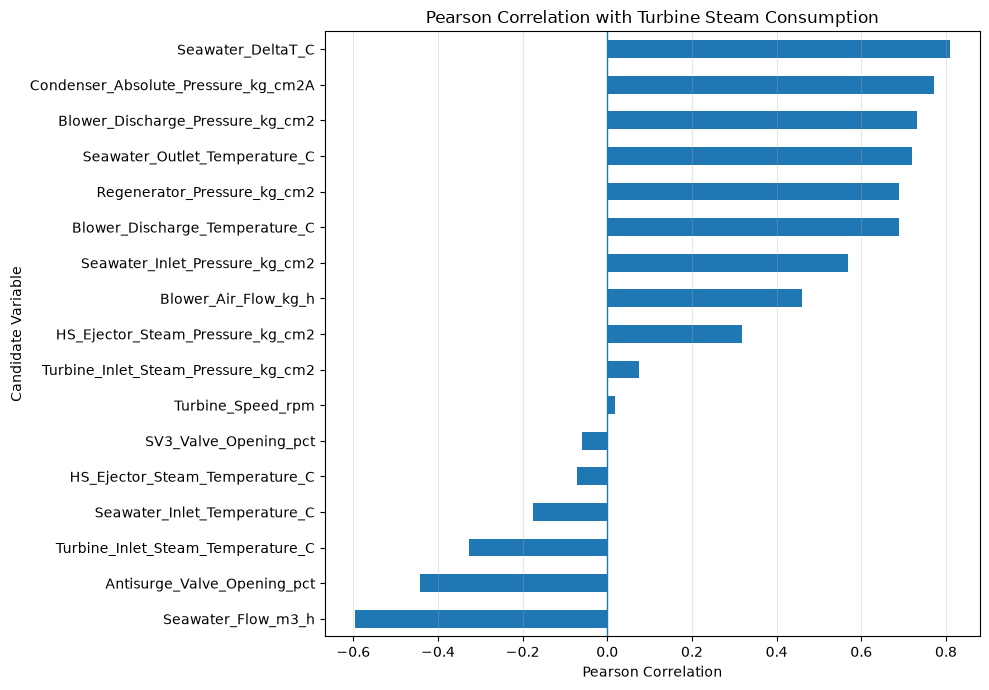

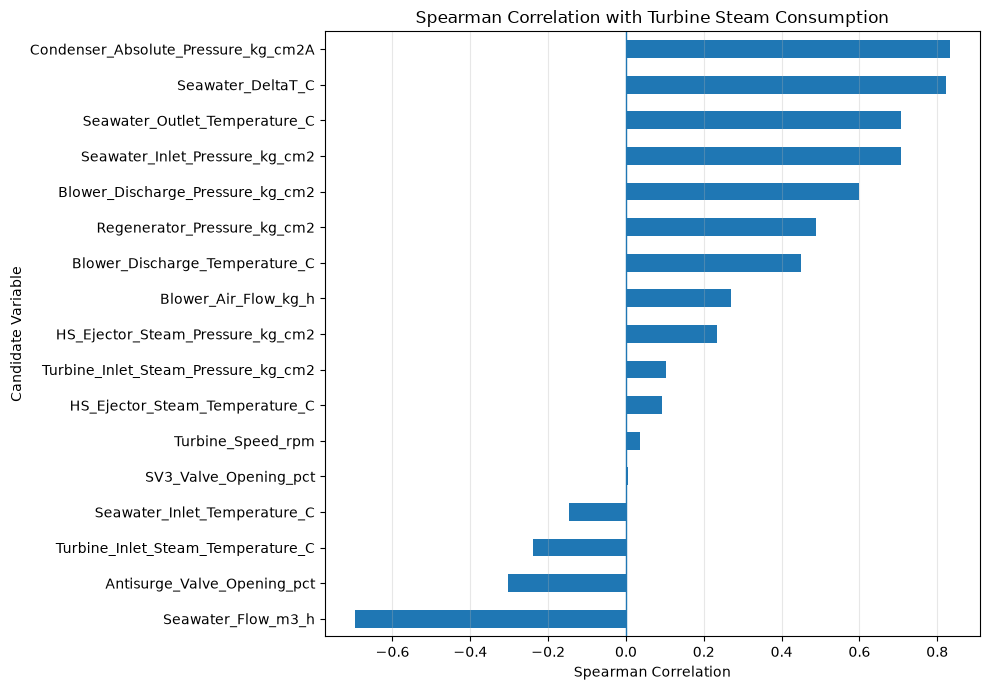

In [17]:
# ============================================================
# ANÁLISIS DE CORRELACIÓN - PEARSON Y SPEARMAN
# TRAIN - SOLO ESTADO IN_SERVICE
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. DEFINIR TARGET
# ============================================================

target = "Turbine_Steam_Consumption_kg_h"


# ============================================================
# 2. DEFINIR VARIABLES CANDIDATAS
# ============================================================

candidate_variables = [

    # Condensador
    "Condenser_Absolute_Pressure_kg_cm2A",

    # Soplador
    "Blower_Air_Flow_kg_h",
    "Blower_Discharge_Temperature_C",
    "Blower_Discharge_Pressure_kg_cm2",

    # Turbina
    "Turbine_Speed_rpm",
    "Turbine_Inlet_Steam_Pressure_kg_cm2",
    "Turbine_Inlet_Steam_Temperature_C",

    # Agua de mar
    "Seawater_Flow_m3_h",
    "Seawater_Inlet_Temperature_C",
    "Seawater_Outlet_Temperature_C",
    "Seawater_DeltaT_C",
    "Seawater_Inlet_Pressure_kg_cm2",

    # Regenerador
    "Regenerator_Pressure_kg_cm2",
    "SV3_Valve_Opening_pct",

    # Antisurge
    "Antisurge_Valve_Opening_pct",

    # Eyectores
    "HS_Ejector_Steam_Pressure_kg_cm2",
    "HS_Ejector_Steam_Temperature_C"
]


# ============================================================
# 3. CREAR DATAFRAME SOLO PARA EL ANÁLISIS
# ============================================================

df_correlation = df_operacion[
    candidate_variables + [target]
].copy()


# Eliminar registros con valores faltantes
df_correlation = df_correlation.dropna()


print("=" * 70)
print("DATOS UTILIZADOS PARA EL ANÁLISIS DE CORRELACIÓN")
print("=" * 70)

print("Registros:", len(df_correlation))
print("Variables candidatas:", len(candidate_variables))
print("Target:", target)


# ============================================================
# 4. CORRELACIÓN DE PEARSON
# ============================================================

pearson_correlation = (
    df_correlation[candidate_variables]
    .corrwith(df_correlation[target], method="pearson")
)


# ============================================================
# 5. CORRELACIÓN DE SPEARMAN
# ============================================================

spearman_correlation = (
    df_correlation[candidate_variables]
    .corrwith(df_correlation[target], method="spearman")
)


# ============================================================
# 6. CREAR TABLA COMPARATIVA
# ============================================================

correlation_results = pd.DataFrame({
    "Pearson": pearson_correlation,
    "Spearman": spearman_correlation
})


# Valor absoluto para facilitar la comparación
correlation_results["Abs_Pearson"] = (
    correlation_results["Pearson"].abs()
)

correlation_results["Abs_Spearman"] = (
    correlation_results["Spearman"].abs()
)


# Ordenar según la correlación absoluta de Pearson
correlation_results = (
    correlation_results
    .sort_values("Abs_Pearson", ascending=False)
)


# ============================================================
# 7. MOSTRAR RESULTADOS
# ============================================================

print("\n" + "=" * 70)
print("CORRELACIÓN CON EL CONSUMO DE VAPOR DE LA TURBINA")
print("=" * 70)

print(
    correlation_results[
        ["Pearson", "Spearman", "Abs_Pearson", "Abs_Spearman"]
    ].round(3)
)


# ============================================================
# 8. GRÁFICO PEARSON
# ============================================================

pearson_plot = (
    correlation_results["Pearson"]
    .sort_values()
)

plt.figure(figsize=(10, 7))

pearson_plot.plot(
    kind="barh"
)

plt.axvline(
    x=0,
    linewidth=1
)

plt.xlabel("Pearson Correlation")
plt.ylabel("Candidate Variable")
plt.title(
    "Pearson Correlation with Turbine Steam Consumption"
)

plt.grid(
    axis="x",
    alpha=0.3
)

plt.tight_layout()
plt.show()


# ============================================================
# 9. GRÁFICO SPEARMAN
# ============================================================

spearman_plot = (
    correlation_results["Spearman"]
    .sort_values()
)

plt.figure(figsize=(10, 7))

spearman_plot.plot(
    kind="barh"
)

plt.axvline(
    x=0,
    linewidth=1
)

plt.xlabel("Spearman Correlation")
plt.ylabel("Candidate Variable")
plt.title(
    "Spearman Correlation with Turbine Steam Consumption"
)

plt.grid(
    axis="x",
    alpha=0.3
)

plt.tight_layout()
plt.show()

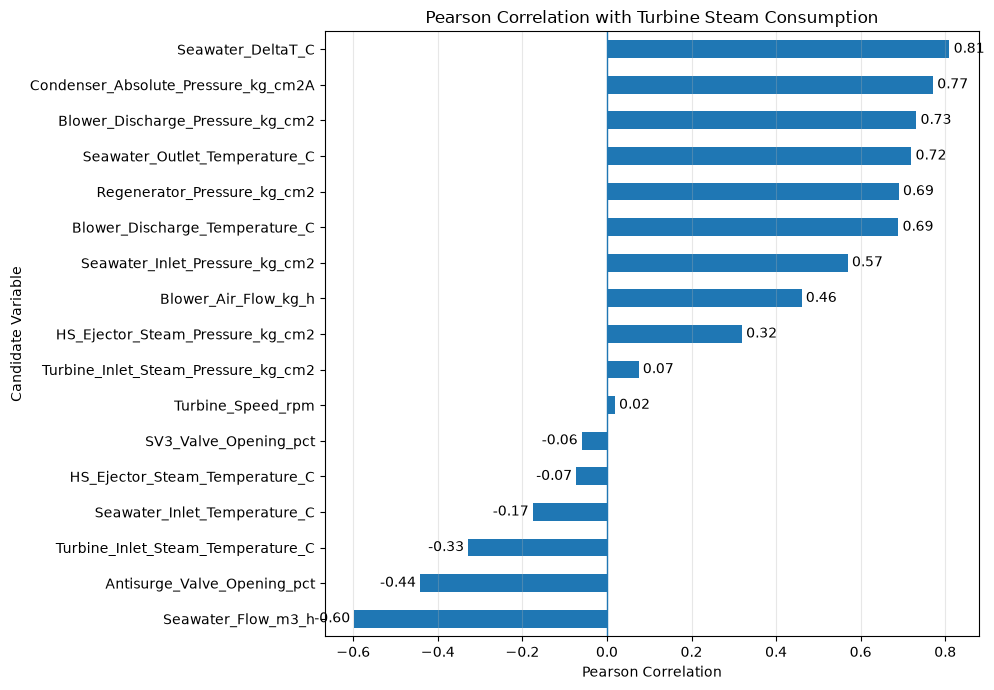

In [16]:
# ============================================================
# 8. GRÁFICO PEARSON CON VALORES EN LAS BARRAS
# ============================================================

pearson_plot = (
    correlation_results["Pearson"]
    .sort_values()
)

plt.figure(figsize=(10, 7))

ax = pearson_plot.plot(
    kind="barh"
)

plt.axvline(
    x=0,
    linewidth=1
)

plt.xlabel("Pearson Correlation")
plt.ylabel("Candidate Variable")
plt.title(
    "Pearson Correlation with Turbine Steam Consumption"
)

plt.grid(
    axis="x",
    alpha=0.3
)

# Agregar valores a las barras
for i, value in enumerate(pearson_plot):

    if value >= 0:
        ax.text(
            value + 0.01,
            i,
            f"{value:.2f}",
            va="center"
        )
    else:
        ax.text(
            value - 0.01,
            i,
            f"{value:.2f}",
            va="center",
            ha="right"
        )

plt.tight_layout()
plt.show()

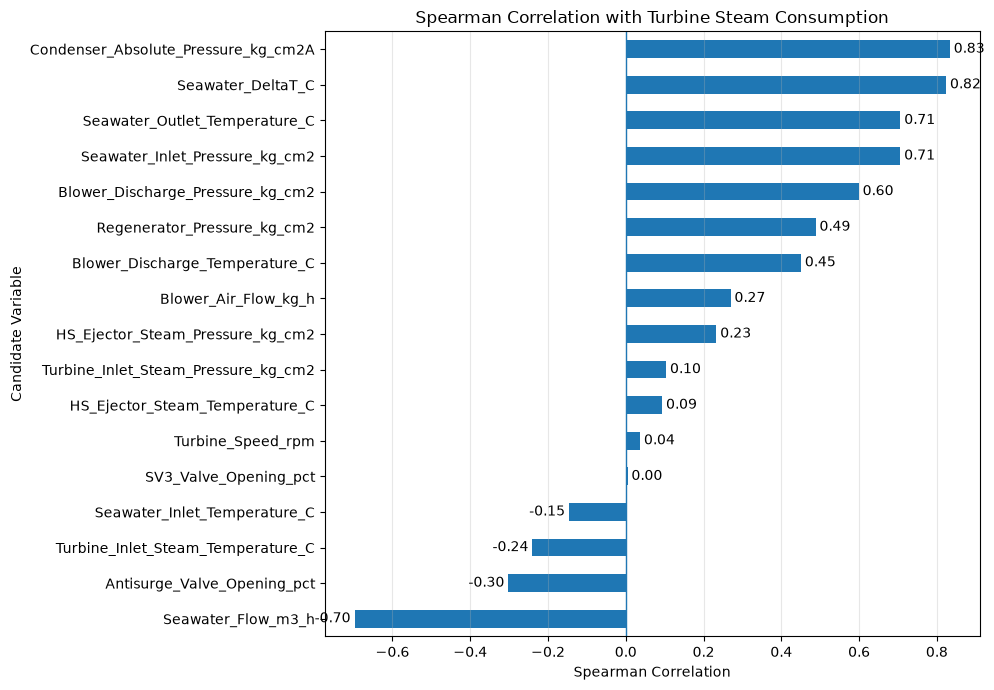

In [17]:
# ============================================================
# 9. GRÁFICO SPEARMAN CON VALORES EN LAS BARRAS
# ============================================================

spearman_plot = (
    correlation_results["Spearman"]
    .sort_values()
)

plt.figure(figsize=(10, 7))

ax = spearman_plot.plot(
    kind="barh"
)

plt.axvline(
    x=0,
    linewidth=1
)

plt.xlabel("Spearman Correlation")
plt.ylabel("Candidate Variable")
plt.title(
    "Spearman Correlation with Turbine Steam Consumption"
)

plt.grid(
    axis="x",
    alpha=0.3
)

# Agregar valores a las barras
for i, value in enumerate(spearman_plot):

    if value >= 0:
        ax.text(
            value + 0.01,
            i,
            f"{value:.2f}",
            va="center"
        )
    else:
        ax.text(
            value - 0.01,
            i,
            f"{value:.2f}",
            va="center",
            ha="right"
        )

plt.tight_layout()
plt.show()

In [20]:
selected_features = [

    # Condensador
    "Condenser_Absolute_Pressure_kg_cm2A",

    # Soplador
    "Blower_Air_Flow_kg_h",
    "Blower_Discharge_Temperature_C",

    # Turbina
    "Turbine_Speed_rpm",
    "Turbine_Inlet_Steam_Pressure_kg_cm2",
    "Turbine_Inlet_Steam_Temperature_C",

    # Agua de mar
    "Seawater_Flow_m3_h",
    "Seawater_Inlet_Temperature_C",
    "Seawater_DeltaT_C",
    "Seawater_Inlet_Pressure_kg_cm2",

    # Regenerador
    "Regenerator_Pressure_kg_cm2",

    # Antisurge
    "Antisurge_Valve_Opening_pct",

    # Eyectores
    "HS_Ejector_Steam_Pressure_kg_cm2",
    "HS_Ejector_Steam_Temperature_C"
]

target = "Turbine_Steam_Consumption_kg_h"

print("Número de variables seleccionadas:", len(selected_features))
print("Target:", target)

Número de variables seleccionadas: 14
Target: Turbine_Steam_Consumption_kg_h


In [19]:
# ============================================================
# OPTIMIZACIÓN DE HIPERPARÁMETROS - 4 MODELOS
# TRAIN - 14 VARIABLES SELECCIONADAS
# ============================================================

import numpy as np
import pandas as pd
import time

from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor
)

from sklearn.model_selection import (
    TimeSeriesSplit,
    RandomizedSearchCV
)


# ============================================================
# 1. DEFINIR LAS 14 VARIABLES SELECCIONADAS
# ============================================================

selected_features = [

    # Condensador
    "Condenser_Absolute_Pressure_kg_cm2A",

    # Soplador
    "Blower_Air_Flow_kg_h",
    "Blower_Discharge_Temperature_C",

    # Turbina
    "Turbine_Speed_rpm",
    "Turbine_Inlet_Steam_Pressure_kg_cm2",
    "Turbine_Inlet_Steam_Temperature_C",

    # Agua de mar
    "Seawater_Flow_m3_h",
    "Seawater_Inlet_Temperature_C",
    "Seawater_DeltaT_C",
    "Seawater_Inlet_Pressure_kg_cm2",

    # Regenerador
    "Regenerator_Pressure_kg_cm2",

    # Antisurge
    "Antisurge_Valve_Opening_pct",

    # Eyectores
    "HS_Ejector_Steam_Pressure_kg_cm2",
    "HS_Ejector_Steam_Temperature_C"
]


# ============================================================
# 2. DEFINIR TARGET
# ============================================================

target = "Turbine_Steam_Consumption_kg_h"


# ============================================================
# 3. PREPARAR TRAIN
# ============================================================

train_data = (
    df_operacion[
        selected_features + [target]
    ]
    .dropna()
    .copy()
)


X_train = train_data[selected_features]
y_train = train_data[target]


print("=" * 70)
print("TAMAÑO DEL CONJUNTO TRAIN")
print("=" * 70)

print("X TRAIN:", X_train.shape)
print("y TRAIN:", y_train.shape)

print("\nNúmero de variables:", len(selected_features))


# ============================================================
# 4. VALIDACIÓN TEMPORAL
# ============================================================

time_series_cv = TimeSeriesSplit(
    n_splits=4
)


print("\n" + "=" * 70)
print("VALIDACIÓN TEMPORAL")
print("=" * 70)


for fold, (train_index, validation_index) in enumerate(
    time_series_cv.split(X_train),
    start=1
):

    print(
        f"Fold {fold}: "
        f"TRAIN = {len(train_index):,} registros | "
        f"VALIDACIÓN = {len(validation_index):,} registros"
    )


# ============================================================
# 5. RANDOM FOREST
# ============================================================

random_forest = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)


random_forest_params = {

    "n_estimators": [
        200,
        300,
        500,
        700
    ],

    "max_depth": [
        None,
        10,
        20,
        30
    ],

    "min_samples_split": [
        2,
        5,
        10,
        20
    ],

    "min_samples_leaf": [
        1,
        2,
        5,
        10,
        20
    ],

    "max_features": [
        "sqrt",
        0.7,
        1.0
    ]
}


rf_search = RandomizedSearchCV(

    estimator=random_forest,

    param_distributions=random_forest_params,

    n_iter=20,

    scoring="neg_mean_absolute_error",

    cv=time_series_cv,

    random_state=42,

    n_jobs=-1,

    verbose=1
)


print("\n" + "=" * 70)
print("OPTIMIZANDO RANDOM FOREST")
print("=" * 70)


inicio = time.time()

rf_search.fit(
    X_train,
    y_train
)

tiempo_rf = time.time() - inicio


print("\nMejores parámetros Random Forest:")
print(rf_search.best_params_)

print(
    "\nMejor MAE CV:",
    round(-rf_search.best_score_, 2),
    "kg/h"
)

print(
    "Tiempo:",
    round(tiempo_rf / 60, 2),
    "minutos"
)


# ============================================================
# 6. EXTRA TREES
# ============================================================

extra_trees = ExtraTreesRegressor(
    random_state=42,
    n_jobs=-1
)


extra_trees_params = {

    "n_estimators": [
        200,
        300,
        500,
        700
    ],

    "max_depth": [
        None,
        10,
        20,
        30
    ],

    "min_samples_split": [
        2,
        5,
        10,
        20
    ],

    "min_samples_leaf": [
        1,
        2,
        5,
        10,
        20
    ],

    "max_features": [
        "sqrt",
        0.7,
        1.0
    ]
}


et_search = RandomizedSearchCV(

    estimator=extra_trees,

    param_distributions=extra_trees_params,

    n_iter=20,

    scoring="neg_mean_absolute_error",

    cv=time_series_cv,

    random_state=42,

    n_jobs=-1,

    verbose=1
)


print("\n" + "=" * 70)
print("OPTIMIZANDO EXTRA TREES")
print("=" * 70)


inicio = time.time()

et_search.fit(
    X_train,
    y_train
)

tiempo_et = time.time() - inicio


print("\nMejores parámetros Extra Trees:")
print(et_search.best_params_)

print(
    "\nMejor MAE CV:",
    round(-et_search.best_score_, 2),
    "kg/h"
)

print(
    "Tiempo:",
    round(tiempo_et / 60, 2),
    "minutos"
)


# ============================================================
# 7. GRADIENT BOOSTING
# ============================================================

gradient_boosting = GradientBoostingRegressor(
    random_state=42
)


gradient_boosting_params = {

    "n_estimators": [
        100,
        200,
        300,
        500
    ],

    "learning_rate": [
        0.01,
        0.03,
        0.05,
        0.08,
        0.1
    ],

    "max_depth": [
        2,
        3,
        4,
        5
    ],

    "min_samples_split": [
        2,
        5,
        10,
        20
    ],

    "min_samples_leaf": [
        1,
        5,
        10,
        20
    ],

    "subsample": [
        0.7,
        0.85,
        1.0
    ]
}


gb_search = RandomizedSearchCV(

    estimator=gradient_boosting,

    param_distributions=gradient_boosting_params,

    n_iter=20,

    scoring="neg_mean_absolute_error",

    cv=time_series_cv,

    random_state=42,

    n_jobs=-1,

    verbose=1
)


print("\n" + "=" * 70)
print("OPTIMIZANDO GRADIENT BOOSTING")
print("=" * 70)


inicio = time.time()

gb_search.fit(
    X_train,
    y_train
)

tiempo_gb = time.time() - inicio


print("\nMejores parámetros Gradient Boosting:")
print(gb_search.best_params_)

print(
    "\nMejor MAE CV:",
    round(-gb_search.best_score_, 2),
    "kg/h"
)

print(
    "Tiempo:",
    round(tiempo_gb / 60, 2),
    "minutos"
)


# ============================================================
# 8. HIST GRADIENT BOOSTING
# ============================================================

hist_gradient_boosting = HistGradientBoostingRegressor(
    random_state=42
)


hist_gradient_boosting_params = {

    "learning_rate": [
        0.03,
        0.05,
        0.08,
        0.1
    ],

    "max_iter": [
        100,
        200,
        300,
        500
    ],

    "max_depth": [
        None,
        3,
        5,
        7,
        10
    ],

    "min_samples_leaf": [
        10,
        20,
        30,
        50
    ],

    "l2_regularization": [
        0.0,
        0.1,
        0.5,
        1.0
    ]
}


hgb_search = RandomizedSearchCV(

    estimator=hist_gradient_boosting,

    param_distributions=hist_gradient_boosting_params,

    n_iter=20,

    scoring="neg_mean_absolute_error",

    cv=time_series_cv,

    random_state=42,

    n_jobs=-1,

    verbose=1
)


print("\n" + "=" * 70)
print("OPTIMIZANDO HIST GRADIENT BOOSTING")
print("=" * 70)


inicio = time.time()

hgb_search.fit(
    X_train,
    y_train
)

tiempo_hgb = time.time() - inicio


print("\nMejores parámetros Hist Gradient Boosting:")
print(hgb_search.best_params_)

print(
    "\nMejor MAE CV:",
    round(-hgb_search.best_score_, 2),
    "kg/h"
)

print(
    "Tiempo:",
    round(tiempo_hgb / 60, 2),
    "minutos"
)


# ============================================================
# 9. RESUMEN DE OPTIMIZACIÓN
# ============================================================

optimization_results = pd.DataFrame({

    "Model": [
        "Random Forest",
        "Extra Trees",
        "Gradient Boosting",
        "Hist Gradient Boosting"
    ],

    "CV_MAE_kg_h": [
        -rf_search.best_score_,
        -et_search.best_score_,
        -gb_search.best_score_,
        -hgb_search.best_score_
    ],

    "Optimization_Time_min": [
        tiempo_rf / 60,
        tiempo_et / 60,
        tiempo_gb / 60,
        tiempo_hgb / 60
    ]
})


optimization_results = (
    optimization_results
    .sort_values("CV_MAE_kg_h")
    .reset_index(drop=True)
)


print("\n" + "=" * 70)
print("RESUMEN DE OPTIMIZACIÓN")
print("=" * 70)

print(
    optimization_results.round(2)
)


# ============================================================
# 10. GUARDAR LOS MEJORES MODELOS
# ============================================================

best_rf = rf_search.best_estimator_

best_et = et_search.best_estimator_

best_gb = gb_search.best_estimator_

best_hgb = hgb_search.best_estimator_


print("\nModelos optimizados guardados correctamente:")
print("best_rf")
print("best_et")
print("best_gb")
print("best_hgb")

TAMAÑO DEL CONJUNTO TRAIN
X TRAIN: (82146, 14)
y TRAIN: (82146,)

Número de variables: 14

VALIDACIÓN TEMPORAL
Fold 1: TRAIN = 16,430 registros | VALIDACIÓN = 16,429 registros
Fold 2: TRAIN = 32,859 registros | VALIDACIÓN = 16,429 registros
Fold 3: TRAIN = 49,288 registros | VALIDACIÓN = 16,429 registros
Fold 4: TRAIN = 65,717 registros | VALIDACIÓN = 16,429 registros

OPTIMIZANDO RANDOM FOREST
Fitting 4 folds for each of 20 candidates, totalling 80 fits

Mejores parámetros Random Forest:
{'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 0.7, 'max_depth': 20}

Mejor MAE CV: 547.95 kg/h
Tiempo: 12.25 minutos

OPTIMIZANDO EXTRA TREES
Fitting 4 folds for each of 20 candidates, totalling 80 fits

Mejores parámetros Extra Trees:
{'n_estimators': 300, 'min_samples_split': 20, 'min_samples_leaf': 1, 'max_features': 1.0, 'max_depth': 30}

Mejor MAE CV: 603.13 kg/h
Tiempo: 2.44 minutos

OPTIMIZANDO GRADIENT BOOSTING
Fitting 4 folds for each of 20 candidates, t

In [20]:
# ============================================================
# EVALUACIÓN FINAL DE LOS 4 MODELOS EN TEST
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


# ============================================================
# 1. PREPARAR TEST
# ============================================================

test_data = (
    df_operacion2[
        selected_features + [target]
    ]
    .dropna()
    .copy()
)


X_test = test_data[selected_features]
y_test = test_data[target]


print("=" * 70)
print("TAMAÑO DEL CONJUNTO TEST")
print("=" * 70)

print("X TEST:", X_test.shape)
print("y TEST:", y_test.shape)

print("\nNúmero de variables:", len(selected_features))


# ============================================================
# 2. REALIZAR PREDICCIONES
# ============================================================

pred_rf = best_rf.predict(X_test)

pred_et = best_et.predict(X_test)

pred_gb = best_gb.predict(X_test)

pred_hgb = best_hgb.predict(X_test)


# ============================================================
# 3. FUNCIÓN PARA CALCULAR MÉTRICAS
# ============================================================

def calculate_metrics(y_real, y_pred):

    mae = mean_absolute_error(
        y_real,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_real,
            y_pred
        )
    )

    r2 = r2_score(
        y_real,
        y_pred
    )

    return mae, rmse, r2


# ============================================================
# 4. CALCULAR MÉTRICAS - RANDOM FOREST
# ============================================================

mae_rf, rmse_rf, r2_rf = calculate_metrics(
    y_test,
    pred_rf
)


# ============================================================
# 5. CALCULAR MÉTRICAS - EXTRA TREES
# ============================================================

mae_et, rmse_et, r2_et = calculate_metrics(
    y_test,
    pred_et
)


# ============================================================
# 6. CALCULAR MÉTRICAS - GRADIENT BOOSTING
# ============================================================

mae_gb, rmse_gb, r2_gb = calculate_metrics(
    y_test,
    pred_gb
)


# ============================================================
# 7. CALCULAR MÉTRICAS - HIST GRADIENT BOOSTING
# ============================================================

mae_hgb, rmse_hgb, r2_hgb = calculate_metrics(
    y_test,
    pred_hgb
)


# ============================================================
# 8. CREAR TABLA COMPARATIVA
# ============================================================

test_results = pd.DataFrame({

    "Model": [
        "Random Forest",
        "Extra Trees",
        "Gradient Boosting",
        "Hist Gradient Boosting"
    ],

    "MAE_kg_h": [
        mae_rf,
        mae_et,
        mae_gb,
        mae_hgb
    ],

    "RMSE_kg_h": [
        rmse_rf,
        rmse_et,
        rmse_gb,
        rmse_hgb
    ],

    "R2": [
        r2_rf,
        r2_et,
        r2_gb,
        r2_hgb
    ]
})


# ============================================================
# 9. AGREGAR MÉTRICAS EN t/h
# ============================================================

test_results["MAE_t_h"] = (
    test_results["MAE_kg_h"] / 1000
)

test_results["RMSE_t_h"] = (
    test_results["RMSE_kg_h"] / 1000
)


# ============================================================
# 10. ORDENAR POR MENOR MAE
# ============================================================

test_results = (
    test_results
    .sort_values("MAE_kg_h")
    .reset_index(drop=True)
)


# ============================================================
# 11. MOSTRAR RESULTADOS
# ============================================================

print("\n" + "=" * 70)
print("RESULTADOS FINALES EN TEST")
print("=" * 70)

print(
    test_results[
        [
            "Model",
            "MAE_kg_h",
            "RMSE_kg_h",
            "MAE_t_h",
            "RMSE_t_h",
            "R2"
        ]
    ].round({
        "MAE_kg_h": 2,
        "RMSE_kg_h": 2,
        "MAE_t_h": 3,
        "RMSE_t_h": 3,
        "R2": 4
    })
)

TAMAÑO DEL CONJUNTO TEST
X TEST: (13261, 14)
y TEST: (13261,)

Número de variables: 14

RESULTADOS FINALES EN TEST
                    Model  MAE_kg_h  RMSE_kg_h  MAE_t_h  RMSE_t_h      R2
0           Random Forest    786.10    1077.47    0.786     1.077  0.8710
1             Extra Trees    820.49    1072.56    0.820     1.073  0.8722
2       Gradient Boosting    846.52    1108.78    0.847     1.109  0.8634
3  Hist Gradient Boosting    847.37    1094.30    0.847     1.094  0.8669


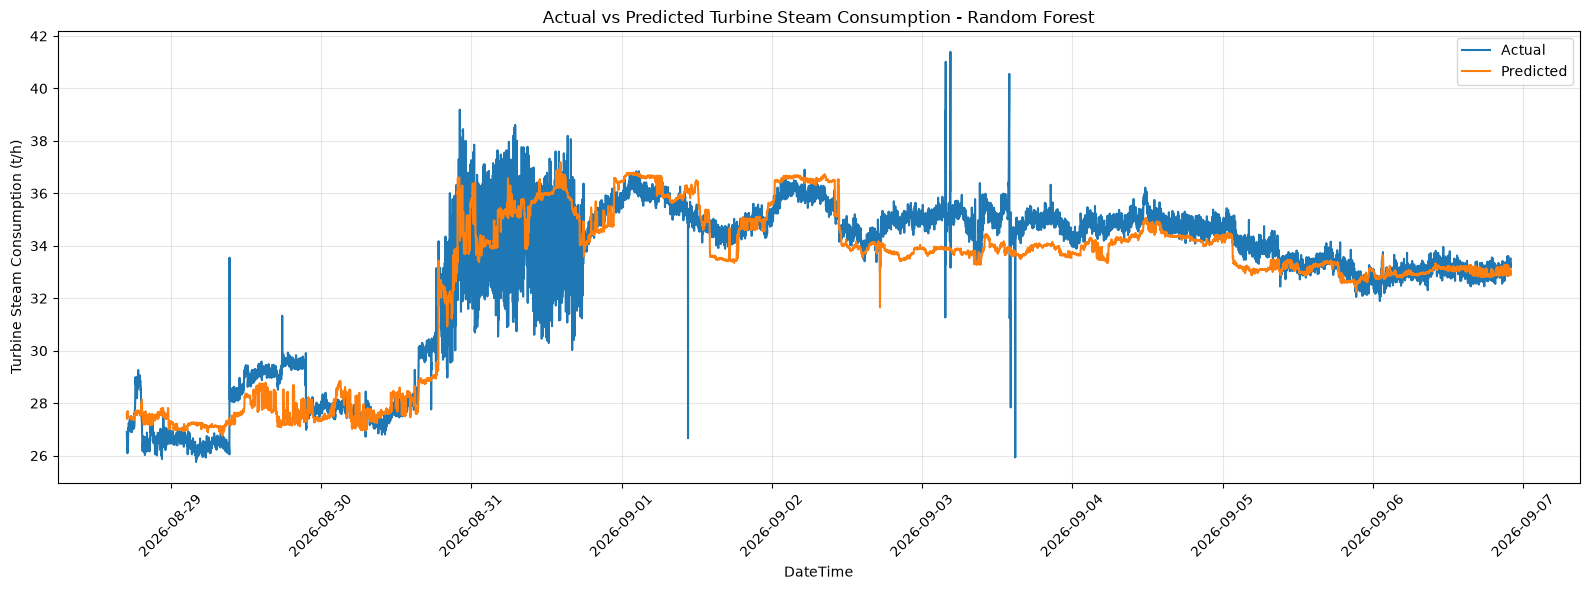

In [21]:
# ============================================================
# GRÁFICA REAL VS PREDICHO - RANDOM FOREST - TEST
# ============================================================

import matplotlib.pyplot as plt


# ============================================================
# 1. CREAR DATAFRAME PARA LA GRÁFICA
# ============================================================

plot_data = test_data.copy()


# Recuperar DateTime desde df_operacion2
# utilizando los mismos índices que quedaron en test_data

plot_data["DateTime"] = df_operacion2.loc[
    plot_data.index,
    "DateTime"
]


# Agregar predicción del Random Forest

plot_data["Predicted_Steam_Consumption_kg_h"] = pred_rf


# ============================================================
# 2. ORDENAR CRONOLÓGICAMENTE
# ============================================================

plot_data = (
    plot_data
    .sort_values("DateTime")
    .reset_index(drop=True)
)


# ============================================================
# 3. CONVERTIR CONSUMO A t/h PARA LA GRÁFICA
# ============================================================

plot_data["Actual_Steam_Consumption_t_h"] = (
    plot_data["Turbine_Steam_Consumption_kg_h"] / 1000
)

plot_data["Predicted_Steam_Consumption_t_h"] = (
    plot_data["Predicted_Steam_Consumption_kg_h"] / 1000
)


# ============================================================
# 4. GRAFICAR REAL VS PREDICHO
# ============================================================

plt.figure(figsize=(16, 6))


plt.plot(
    plot_data["DateTime"],
    plot_data["Actual_Steam_Consumption_t_h"],
    label="Actual",
    linewidth=1.5
)


plt.plot(
    plot_data["DateTime"],
    plot_data["Predicted_Steam_Consumption_t_h"],
    label="Predicted",
    linewidth=1.5
)


plt.xlabel("DateTime")

plt.ylabel(
    "Turbine Steam Consumption (t/h)"
)

plt.title(
    "Actual vs Predicted Turbine Steam Consumption - Random Forest"
)


plt.legend()


plt.grid(
    alpha=0.3
)


plt.xticks(
    rotation=45
)


plt.tight_layout()

plt.show()

c:\Users\diego\Documents\primer_python\01-python-intro\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ANÁLISIS SHAP - RANDOM FOREST
Modelo: Random Forest
Registros utilizados para SHAP: 2000
Variables: 14

Valores SHAP calculados correctamente.

IMPORTANCIA GLOBAL SHAP
                               Variable  Mean_Abs_SHAP_kg_h  \
0        Blower_Discharge_Temperature_C              867.86   
1   Condenser_Absolute_Pressure_kg_cm2A              620.48   
2           Regenerator_Pressure_kg_cm2              537.07   
3                     Seawater_DeltaT_C              525.44   
4        Seawater_Inlet_Pressure_kg_cm2              192.72   
5     Turbine_Inlet_Steam_Temperature_C              175.38   
6           Antisurge_Valve_Opening_pct               86.96   
7                    Seawater_Flow_m3_h               82.78   
8   Turbine_Inlet_Steam_Pressure_kg_cm2               78.44   
9          Seawater_Inlet_Temperature_C               70.60   
10                 Blower_Air_Flow_kg_h               41.84   
11       HS_Ejector_Steam_Temperature_C               34.29   
12     HS_Eje

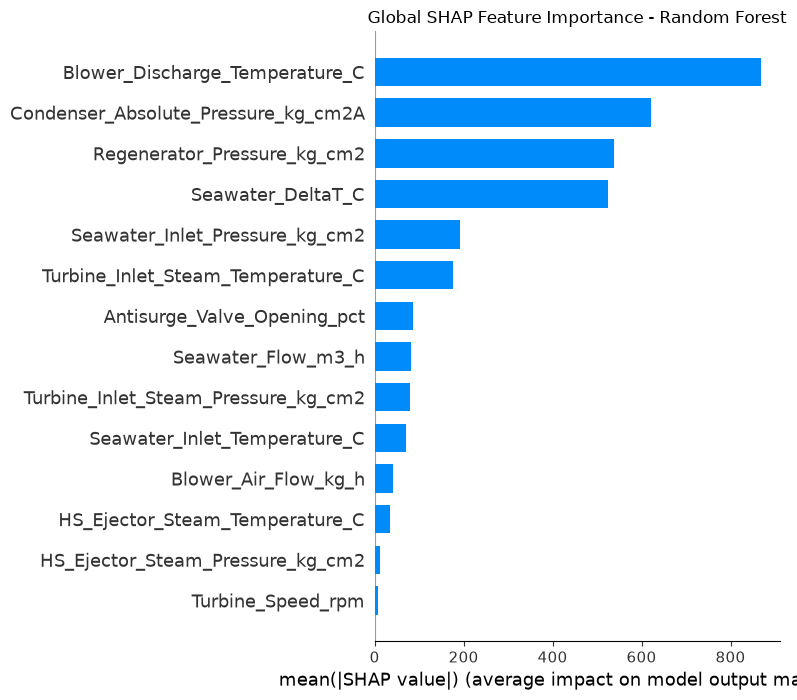

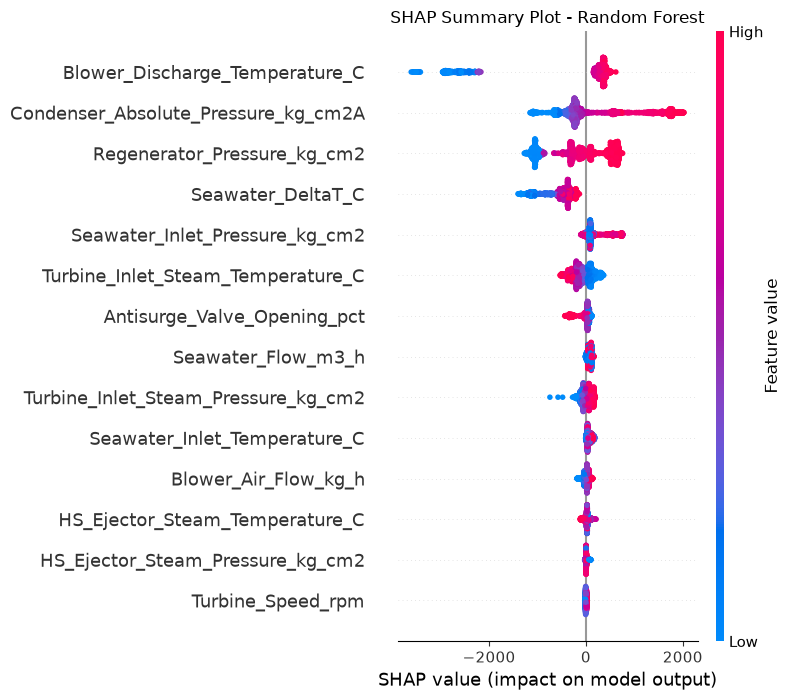

In [25]:
# ============================================================
# SHAP - INTERPRETACIÓN DEL MODELO RANDOM FOREST
# ============================================================

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. SELECCIONAR UNA MUESTRA DEL TEST
# ============================================================

# Se utilizan 2000 registros para reducir el tiempo de cálculo
# manteniendo una muestra representativa del conjunto TEST.

SHAP_SAMPLE_SIZE = min(2000, len(X_test))

X_shap = X_test.sample(
    n=SHAP_SAMPLE_SIZE,
    random_state=42
)


print("=" * 70)
print("ANÁLISIS SHAP - RANDOM FOREST")
print("=" * 70)

print("Modelo: Random Forest")
print("Registros utilizados para SHAP:", len(X_shap))
print("Variables:", X_shap.shape[1])


# ============================================================
# 2. CREAR EXPLICADOR SHAP
# ============================================================

explainer = shap.TreeExplainer(
    best_rf
)


# ============================================================
# 3. CALCULAR VALORES SHAP
# ============================================================

shap_values = explainer.shap_values(
    X_shap
)


print("\nValores SHAP calculados correctamente.")


# ============================================================
# 4. CALCULAR IMPORTANCIA GLOBAL
# ============================================================

mean_abs_shap = np.abs(
    shap_values
).mean(axis=0)


shap_importance = pd.DataFrame({

    "Variable": X_shap.columns,

    "Mean_Abs_SHAP_kg_h": mean_abs_shap

})


shap_importance = (
    shap_importance
    .sort_values(
        "Mean_Abs_SHAP_kg_h",
        ascending=False
    )
    .reset_index(drop=True)
)


# Agregar importancia relativa (%)

shap_importance["Relative_Importance_pct"] = (
    shap_importance["Mean_Abs_SHAP_kg_h"]
    / shap_importance["Mean_Abs_SHAP_kg_h"].sum()
    * 100
)


# ============================================================
# 5. MOSTRAR RANKING
# ============================================================

print("\n" + "=" * 70)
print("IMPORTANCIA GLOBAL SHAP")
print("=" * 70)

print(
    shap_importance.round({
        "Mean_Abs_SHAP_kg_h": 2,
        "Relative_Importance_pct": 2
    })
)


# ============================================================
# 6. GRÁFICA SHAP DE IMPORTANCIA GLOBAL
# ============================================================

shap.summary_plot(
    shap_values,
    X_shap,
    plot_type="bar",
    show=False
)

plt.title(
    "Global SHAP Feature Importance - Random Forest"
)

plt.tight_layout()

plt.show()


# ============================================================
# 7. SHAP SUMMARY PLOT - BEESWARM
# ============================================================

shap.summary_plot(
    shap_values,
    X_shap,
    show=False
)

plt.title(
    "SHAP Summary Plot - Random Forest"
)

plt.tight_layout()

plt.show()

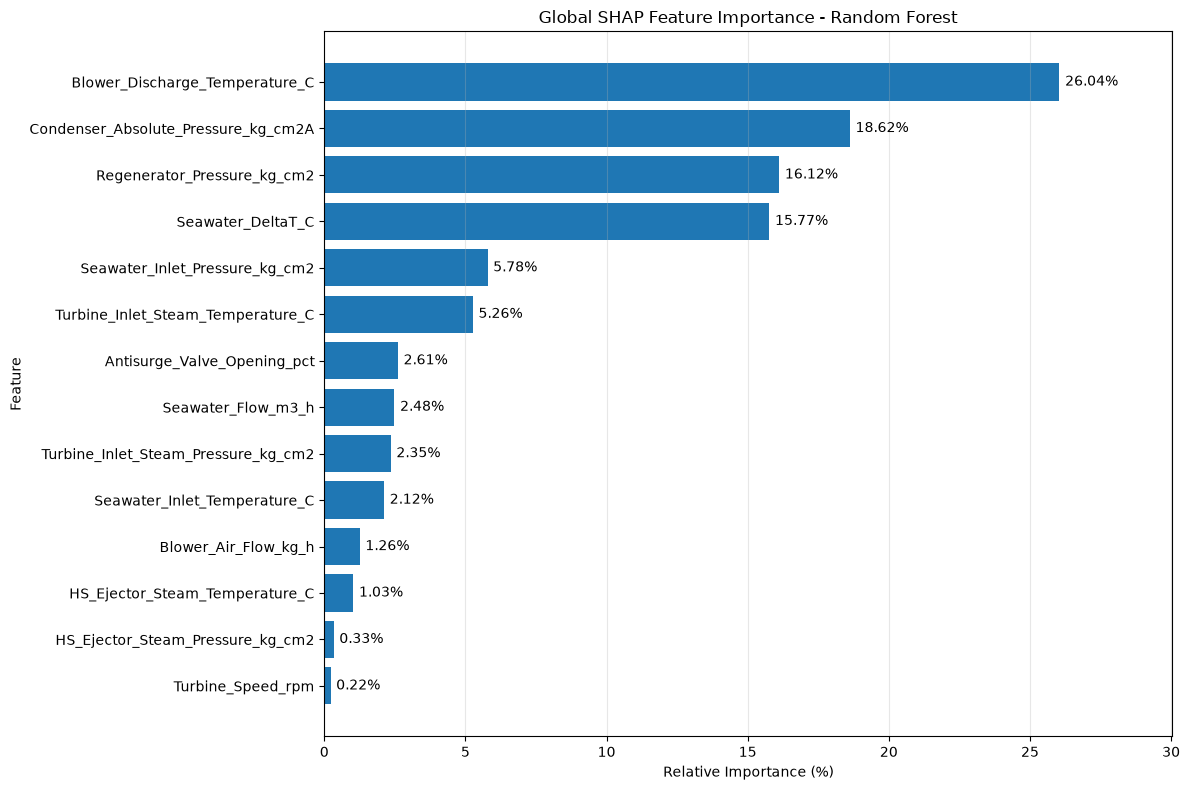

In [26]:
# ============================================================
# GRÁFICA SHAP - IMPORTANCIA RELATIVA EN %
# RANDOM FOREST
# ============================================================

import matplotlib.pyplot as plt


# ============================================================
# 1. ORDENAR VARIABLES POR IMPORTANCIA
# ============================================================

shap_plot = (
    shap_importance
    .sort_values(
        "Relative_Importance_pct",
        ascending=True
    )
    .copy()
)


# ============================================================
# 2. CREAR GRÁFICA
# ============================================================

plt.figure(figsize=(12, 8))

ax = plt.barh(
    shap_plot["Variable"],
    shap_plot["Relative_Importance_pct"]
)


# ============================================================
# 3. AGREGAR PORCENTAJE EN CADA BARRA
# ============================================================

for i, value in enumerate(
    shap_plot["Relative_Importance_pct"]
):

    plt.text(
        value + 0.2,
        i,
        f"{value:.2f}%",
        va="center"
    )


# ============================================================
# 4. CONFIGURACIÓN DEL GRÁFICO
# ============================================================

plt.xlabel(
    "Relative Importance (%)"
)

plt.ylabel(
    "Feature"
)

plt.title(
    "Global SHAP Feature Importance - Random Forest"
)

plt.grid(
    axis="x",
    alpha=0.3
)

plt.xlim(
    0,
    shap_plot["Relative_Importance_pct"].max() + 4
)

plt.tight_layout()

plt.show()